# Data & AI Salaries: Exploratory Analysis and Salary Prediction

**Goal:** understand what drives salaries in data and AI jobs, and build a model that predicts `salary_in_usd`.

**Dataset:** 13,972 salary records (2020 to 2024) for data and AI roles in 77 company countries, with 11 columns.

**How this notebook is organised** (it follows the Unit 3 EDA workflow):

1. Understand the data: structure, target, problem type, feature types
2. Data quality and cleaning: missing values, whitespace, duplicates, invalid values, outliers, currency
3. Feature engineering: new columns that make the data easier to read and to model
4. Univariate analysis: one variable at a time
5. Bivariate analysis: how each factor relates to salary
6. Saudi Arabia in a global context: external Saudi salary benchmarks
7. From EDA to machine learning: feature selection, leakage, model comparison, final model
8. Key findings and limitations

All amounts are in **US dollars per year** unless stated otherwise. Saudi riyal (SAR) figures use the fixed peg of **1 USD = 3.75 SAR**.

### Where this fits in the data science workflow

| Workflow step | In this notebook |
|---|---|
| **Ask** (define the problem) | What drives data and AI salaries, and can we predict them? |
| **Prepare** (collect data) | `data/salaries.csv` plus published Saudi benchmarks (section 6) |
| **Process** (clean and transform) | Sections 2 and 3 |
| **Analyze** (EDA and modelling) | Sections 4, 5 and 7 |
| **Act** (decisions) | Section 8 and the Streamlit app |

EDA turns **data** into **information** and **insight**: the raw salary records (data) become summaries such as "Senior roles earn a median of $155,000" (information), which lead to conclusions such as "experience and location matter more than company size" (insight) that a job seeker or HR team can act on (value).
EDA mainly supports **descriptive** analytics (what happened?) and **diagnostic** analytics (why did it happen?). The model in section 7 adds **predictive** analytics (what will a profile earn?).

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from src import features as F
from src import modeling as M
from src import style as S

S.apply_matplotlib_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
K = mticker.FuncFormatter(S.money_k)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()


def usd(x):
    return f"${x:,.0f}"


def sar_month(x):
    return f"{x * F.USD_TO_SAR / 12:,.0f} SAR/month"

## 1. Understand the data

### 1.1 First look

In [2]:
raw = pd.read_csv(F.DATA_PATH)
print("Rows, columns:", raw.shape)
raw.head()

Rows, columns: (13972, 11)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2024,SE,FT,AI Engineer,90000,USD,90000,AE,0,AE,L
1,2024,SE,FT,Machine Learning Engineer,180500,USD,180500,US,0,US,M
2,2024,SE,FT,Machine Learning Engineer,96200,USD,96200,US,0,US,M
3,2024,SE,FT,Machine Learning Engineer,235000,USD,235000,AU,0,AU,M
4,2024,SE,FT,Machine Learning Engineer,175000,USD,175000,AU,0,AU,M


In [3]:
raw.columns.tolist()

['work_year',
 'experience_level',
 'employment_type',
 'job_title',
 'salary',
 'salary_currency',
 'salary_in_usd',
 'employee_residence',
 'remote_ratio',
 'company_location',
 'company_size']

In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 13972 entries, 0 to 13971
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   work_year           13972 non-null  int64
 1   experience_level    13972 non-null  str  
 2   employment_type     13972 non-null  str  
 3   job_title           13972 non-null  str  
 4   salary              13972 non-null  int64
 5   salary_currency     13972 non-null  str  
 6   salary_in_usd       13972 non-null  int64
 7   employee_residence  13972 non-null  str  
 8   remote_ratio        13972 non-null  int64
 9   company_location    13972 non-null  str  
 10  company_size        13972 non-null  str  
dtypes: int64(4), str(7)
memory usage: 1.5 MB


In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
work_year,"13,972.00","2,023.09",0.69,"2,020.00","2,023.00","2,023.00","2,024.00","2,024.00"
salary,"13,972.00","166,001.13","366,154.50","14,000.00","104,000.00","142,200.00","188,000.00","30,400,000.00"
salary_in_usd,"13,972.00","150,028.81","68,634.31","15,000.00","103,000.00","141,600.00","185,900.00","800,000.00"
remote_ratio,"13,972.00",33.33,46.68,0.00,0.00,0.00,100.00,100.00


In [6]:
raw.describe(exclude="number").T

,count,unique,top,freq
experience_level,13972,4,SE,9248
employment_type,13972,4,FT,13912
job_title,13972,146,Data Engineer,3017
salary_currency,13972,23,USD,12876
employee_residence,13972,88,US,12171
company_location,13972,77,US,12220
company_size,13972,3,M,12831


### 1.2 What each column means

| Column | Meaning | Type |
|---|---|---|
| `work_year` | Year the salary was paid | Numerical (year) |
| `experience_level` | EN = Entry, MI = Mid, SE = Senior, EX = Executive | Categorical, ordered |
| `employment_type` | FT = Full-time, PT = Part-time, CT = Contract, FL = Freelance | Categorical |
| `job_title` | Job title (146 different titles) | Categorical |
| `salary` | Gross salary in the original currency | Numerical |
| `salary_currency` | Currency of `salary` | Categorical |
| `salary_in_usd` | **Salary converted to USD (the target)** | Numerical |
| `employee_residence` | Country where the employee lives (ISO code) | Categorical |
| `remote_ratio` | 0 = on-site, 50 = hybrid, 100 = fully remote | Categorical (coded as numbers) |
| `company_location` | Country of the employer (ISO code) | Categorical |
| `company_size` | S = Small, M = Medium, L = Large | Categorical, ordered |

### 1.3 Target and problem type

* **Target:** `salary_in_usd`, the column we want to predict.
* It is a continuous number, so this is a **regression** problem.
* `salary` is the same value in a different currency, so it must never be used as a feature (that would be **data leakage**).

### 1.4 Feature types

In [7]:
feature_types = pd.DataFrame({
    "column": raw.columns,
    "pandas dtype": raw.dtypes.astype(str).values,
    "unique values": raw.nunique().values,
    "feature type": ["Date/Time (year)", "Categorical (ordinal)", "Categorical", "Categorical",
                     "Numerical", "Categorical", "Numerical", "Categorical", "Categorical (stored as numbers)",
                     "Categorical", "Categorical (ordinal)"],
    "role": ["feature", "feature", "feature", "feature (146 values, will be grouped)",
             "excluded: leakage", "excluded: leakage", "TARGET", "excluded: redundant",
             "feature", "feature", "feature"],
})
feature_types

,column,pandas dtype,unique values,feature type,role
0,work_year,int64,5,Date/Time (year),feature
1,experience_level,str,4,Categorical (ordinal),feature
2,employment_type,str,4,Categorical,feature
3,job_title,str,146,Categorical,"feature (146 values, will be grouped)"
4,salary,int64,2237,Numerical,excluded: leakage
5,salary_currency,str,23,Categorical,excluded: leakage
6,salary_in_usd,int64,2596,Numerical,TARGET
7,employee_residence,str,88,Categorical,excluded: redundant
8,remote_ratio,int64,3,Categorical (stored as numbers),feature
9,company_location,str,77,Categorical,feature


There are no Boolean (True/False) columns in the raw data; section 3 creates a few (`is_us`, `is_management`, `cross_border`, `is_outlier`).

**Answers to the first questions** (Unit 3, Part 1): 13,972 rows and 11 columns; the names and meanings are in the table above; the target is `salary_in_usd`; the problem is **regression**; the feature types are listed above.

## 2. Data quality and cleaning

### 2.1 Missing values

In [8]:
missing = raw.isna().sum()
print("Total missing values:", int(missing.sum()))
missing.to_frame("missing").T

Total missing values: 0


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
missing,0,0,0,0,0,0,0,0,0,0,0


**Result:** no missing values in any column. The usual options (remove rows, remove columns, fill with the mean or median, fill with the most frequent value, or keep) are therefore not needed here.

### 2.2 Hidden whitespace check with `strip()`

Duplicates or extra categories can be caused by invisible spaces (for example `"Data Engineer "` vs `"Data Engineer"`).
We compare every text column before and after `str.strip()`, and also look for double spaces, case differences and non-breaking spaces.

In [9]:
text_cols = raw.select_dtypes(exclude="number").columns
checks = []
for col in text_cols:
    s = raw[col].astype(str)
    checks.append({
        "column": col,
        "values changed by strip()": int((s != s.str.strip()).sum()),
        "double spaces": int(s.str.contains(r"\s{2,}", regex=True).sum()),
        "non-breaking spaces": int(s.str.contains("\u00a0").sum()),
        "unique before": s.nunique(),
        "unique after strip": s.str.strip().nunique(),
        "unique after strip + lower": s.str.strip().str.lower().nunique(),
    })
whitespace = pd.DataFrame(checks).set_index("column")
whitespace

,values changed by strip(),double spaces,non-breaking spaces,unique before,unique after strip,unique after strip + lower
column,,,,,,
experience_level,0,0,0,4,4,4
employment_type,0,0,0,4,4,4
job_title,0,0,0,146,146,146
salary_currency,0,0,0,23,23,23
employee_residence,0,0,0,88,88,88
company_location,0,0,0,77,77,77
company_size,0,0,0,3,3,3


In [10]:
stripped = raw.copy()
stripped[text_cols] = stripped[text_cols].apply(lambda s: s.astype(str).str.strip())
dup_before = int(raw.duplicated().sum())
dup_after = int(stripped.duplicated().sum())
print(f"Exact duplicate rows before strip(): {dup_before:,}")
print(f"Exact duplicate rows after strip():  {dup_after:,}")
assert whitespace.iloc[:, 0].sum() == 0 and dup_before == dup_after

Exact duplicate rows before strip(): 5,378
Exact duplicate rows after strip():  5,378


**Result:** no text value has leading or trailing spaces, double spaces, hidden non-breaking spaces or case variants. `strip()` changes nothing, and the number of exact duplicate rows stays at **5,378**. The duplicates are genuinely identical records, not a formatting problem.

### 2.3 Duplicate rows: keep or drop?

There is no ID column, so we cannot tell whether two identical rows are the same person entered twice or two people with the same job and salary (for example, a large company paying a standard salary band).
Instead of guessing, we measure the effect of both choices.

In [11]:
key_cols = F.RAW_COLUMNS
dup_mask = raw.duplicated(keep=False)
group_sizes = raw.groupby(key_cols).size()
print(f"Rows: {len(raw):,} | unique rows: {len(group_sizes):,} | extra copies: {dup_before:,} ({dup_before / len(raw):.1%})")
print(f"Largest group of identical rows: {group_sizes.max()} copies")
print()
print("Share of rows that have an identical twin, by year:")
print(raw.assign(dup=dup_mask).groupby("work_year")["dup"].mean().map("{:.0%}".format).to_string())
group_sizes.sort_values(ascending=False).head(5).rename("copies").reset_index()

Rows: 13,972 | unique rows: 8,594 | extra copies: 5,378 (38.5%)
Largest group of identical rows: 54 copies

Share of rows that have an identical twin, by year:
work_year
2020     0%
2021     2%
2022    47%
2023    61%
2024    42%


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size,copies
0,2023,SE,FT,Applied Scientist,136000,USD,136000,US,0,US,L,54
1,2023,SE,FT,Machine Learning Engineer,204500,USD,204500,US,0,US,M,35
2,2023,SE,FT,Machine Learning Engineer,142200,USD,142200,US,0,US,M,34
3,2023,SE,FT,Applied Scientist,222200,USD,222200,US,0,US,L,29
4,2023,SE,FT,Data Scientist,129300,USD,129300,US,0,US,M,26


**Effect on the descriptive statistics**

In [12]:
unique_rows = raw.drop_duplicates()
compare = pd.DataFrame({
    "Keep duplicates": [len(raw), raw.salary_in_usd.median(), raw.salary_in_usd.mean(),
                        (raw.company_location == "US").mean()],
    "Drop duplicates": [len(unique_rows), unique_rows.salary_in_usd.median(), unique_rows.salary_in_usd.mean(),
                        (unique_rows.company_location == "US").mean()],
}, index=["rows", "median salary", "mean salary", "share of US companies"])
compare.loc["share of US companies"] = compare.loc["share of US companies"] * 100
compare.round(1)

,Keep duplicates,Drop duplicates
rows,"13,972.00","8,594.00"
median salary,"141,600.00","138,750.00"
mean salary,"150,028.80","146,745.20"
share of US companies,87.50,82.30


**Effect on the model**

A fair test needs the *same* test rows for both choices, and no row may appear in both train and test.
We split by unique row (`GroupShuffleSplit`), train once with duplicates and once without, and score both on the same unique test rows. Repeated with 5 different random splits.

In [13]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit, train_test_split

groups = raw.groupby(key_cols).ngroup().values
dup_rows = []
for seed in range(5):
    tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(raw, groups=groups))
    tr, te = raw.iloc[tr_idx], raw.iloc[te_idx]
    te_unique = te.drop_duplicates()
    for strategy, train_rows in {"Keep duplicates": tr, "Drop duplicates": tr.drop_duplicates()}.items():
        for name, est, scale in [("Linear Regression", LinearRegression(), True),
                                 ("Gradient Boosting", HistGradientBoostingRegressor(random_state=42), False)]:
            pipe = M.make_pipeline(est, scale, log_target=True).fit(train_rows[F.MODEL_INPUTS], train_rows[F.TARGET])
            scores = M.regression_metrics(te_unique[F.TARGET], pipe.predict(te_unique[F.MODEL_INPUTS]))
            dup_rows.append({"seed": seed, "model": name, "training data": strategy, **scores})

dup_results = (pd.DataFrame(dup_rows).groupby(["model", "training data"])[["MAE", "RMSE", "R2"]]
               .mean().round(3))
dup_results

MAE      RMSE   R2
model             training data                           
Gradient Boosting Drop duplicates 41,314.20 60,212.06 0.31
                  Keep duplicates 41,402.80 60,387.73 0.31
Linear Regression Drop duplicates 41,562.28 60,576.65 0.30
                  Keep duplicates 41,491.25 60,523.31 0.30

In [14]:
# What happens with a naive random split when duplicates are kept?
tr_naive, te_naive = train_test_split(raw, test_size=0.2, random_state=42)
train_keys = set(map(tuple, tr_naive[key_cols].values))
leak_share = np.mean([tuple(r) in train_keys for r in te_naive[key_cols].values])
print(f"With a naive split, {leak_share:.1%} of test rows also appear, identically, in the training data.")

With a naive split, 50.2% of test rows also appear, identically, in the training data.


**What we found**

* 5,378 rows (38.5%) are exact copies of another row. The largest group is 54 identical rows (Senior Applied Scientist, large US company, $136,000), which looks like many employees on the same salary band rather than a typing error.
* Duplicates are almost absent in 2020 and 2021 and very common from 2022 onward.
* The descriptive statistics barely move: the median goes from $141,600 to $138,750 and the US share from 87.5% to 82.3%.
* Model accuracy is practically the same either way (differences under $100 in MAE, same R²).
* But with a normal random split, **50.2% of test rows would be exact copies of training rows**, which makes the measured accuracy less trustworthy.

**Decision**

* **Charts and statistics:** keep all 13,972 rows. They are real records and removing them changes little.
* **Model:** train on the 8,594 unique rows. Accuracy is the same, and it guarantees no test row is a copy of a training row, so the reported accuracy is honest.

### 2.4 Data types and invalid values

First, are numbers stored as numbers? (A common problem is a numeric column stored as text.)

In [15]:
expected_numeric = ["work_year", "salary", "salary_in_usd", "remote_ratio"]
pd.DataFrame({"dtype": raw[expected_numeric].dtypes.astype(str),
              "is numeric": [pd.api.types.is_numeric_dtype(raw[c]) for c in expected_numeric]})

,dtype,is numeric
work_year,int64,True
salary,int64,True
salary_in_usd,int64,True
remote_ratio,int64,True


Next, are the values logically valid?

In [16]:
problems = {
    "salary <= 0": int((raw.salary <= 0).sum()),
    "salary_in_usd <= 0": int((raw.salary_in_usd <= 0).sum()),
    "remote_ratio not in {0, 50, 100}": int((~raw.remote_ratio.isin([0, 50, 100])).sum()),
    "experience_level not in {EN, MI, SE, EX}": int((~raw.experience_level.isin(F.EXPERIENCE_LABELS)).sum()),
    "company_size not in {S, M, L}": int((~raw.company_size.isin(F.COMPANY_SIZE_LABELS)).sum()),
    "employment_type not in {FT, PT, CT, FL}": int((~raw.employment_type.isin(F.EMPLOYMENT_LABELS)).sum()),
    "unknown country codes": int((~raw.company_location.isin(F.COUNTRY_NAMES) | ~raw.employee_residence.isin(F.COUNTRY_NAMES)).sum()),
    "USD rows where salary != salary_in_usd": int(((raw.salary_currency == "USD") & (raw.salary != raw.salary_in_usd)).sum()),
    "work_year outside 2020 to 2024": int((~raw.work_year.between(2020, 2024)).sum()),
}
pd.Series(problems, name="rows with a problem").to_frame()

,rows with a problem
salary <= 0,0
salary_in_usd <= 0,0
"remote_ratio not in {0, 50, 100}",0
"experience_level not in {EN, MI, SE, EX}",0
"company_size not in {S, M, L}",0
"employment_type not in {FT, PT, CT, FL}",0
unknown country codes,0
USD rows where salary != salary_in_usd,0
work_year outside 2020 to 2024,0


**Result:** no invalid values. Every salary is positive, every code is valid, all years are 2020 to 2024, and for USD rows `salary` equals `salary_in_usd` as expected. Numbers are already stored as integers and categories as text, so no type conversion is needed.

### 2.5 Outliers (IQR method)

In [17]:
# IQR method, step by step
Q1 = raw.salary_in_usd.quantile(0.25)
Q3 = raw.salary_in_usd.quantile(0.75)
IQR = Q3 - Q1
low_b = Q1 - 1.5 * IQR
high_b = Q3 + 1.5 * IQR
print(f"1. Q1 = {usd(Q1)}")
print(f"2. Q3 = {usd(Q3)}")
print(f"3. IQR = Q3 - Q1 = {usd(IQR)}")
print(f"4. Lower bound = Q1 - 1.5 x IQR = {usd(low_b)}")
print(f"5. Upper bound = Q3 + 1.5 x IQR = {usd(high_b)}")
assert (low_b, high_b) == F.iqr_bounds(raw.salary_in_usd)
outliers = raw[(raw.salary_in_usd < low_b) | (raw.salary_in_usd > high_b)]
print()
print(f"Outliers: {len(outliers):,} rows ({len(outliers) / len(raw):.1%}), all on the high side: {bool((outliers.salary_in_usd > high_b).all())}")
print()
print("Who are the outliers?")
print(outliers.experience_level.map(F.EXPERIENCE_LABELS).value_counts(normalize=True).map("{:.0%}".format).to_string())
print("Share in US companies:", f"{(outliers.company_location == 'US').mean():.0%}")
outliers.sort_values("salary_in_usd", ascending=False).head(8)[
    ["work_year", "experience_level", "job_title", "salary_in_usd", "company_location", "company_size"]]

1. Q1 = $103,000
2. Q3 = $185,900
3. IQR = Q3 - Q1 = $82,900
4. Lower bound = Q1 - 1.5 x IQR = $-21,350
5. Upper bound = Q3 + 1.5 x IQR = $310,250

Outliers: 253 rows (1.8%), all on the high side: True

Who are the outliers?
experience_level
Senior       75%
Mid          14%
Executive    10%
Entry         1%
Share in US companies: 95%


,work_year,experience_level,job_title,salary_in_usd,company_location,company_size
242,2024,MI,AI Architect,800000,CA,M
1085,2024,EN,Data Analyst,774000,MX,M
1884,2024,SE,Analytics Engineer,750000,US,M
2060,2024,MI,Machine Learning Scientist,750000,US,M
2471,2024,SE,Data Analyst,750000,US,M
3850,2023,MI,Machine Learning Engineer,750000,US,M
3844,2023,MI,Machine Learning Scientist,750000,US,M
4936,2023,SE,Data Scientist,750000,US,M


**Decision: keep the outliers.** 253 salaries (1.8%) are above $310,250. All of them are on the high side, 95% are at US companies and 85% are Senior or Executive, which is what real top salaries look like. Deleting them would hide real information. Instead we:

1. flag them with an `is_outlier` column,
2. use the median (not the mean) in the charts, and
3. test a log-transformed target in the model, which reduces their pull.

A few values look suspicious (for example an Entry-level Data Analyst in Mexico at $774,000), but they cannot be verified and are too few to change the results.

### 2.6 Does showing salaries in SAR change anything?

The riyal is pegged at 3.75 per dollar, so SAR is a fixed multiple of USD. We check that converting does not change the cleaning or the model.

In [18]:
from sklearn.linear_model import Ridge

chk = raw.drop_duplicates().copy()
chk["salary_sar"] = chk.salary_in_usd * F.USD_TO_SAR
iqr_usd = F.iqr_bounds(chk.salary_in_usd)
iqr_sar = F.iqr_bounds(chk.salary_sar)
same_outliers = ((chk.salary_in_usd > iqr_usd[1]) == (chk.salary_sar > iqr_sar[1])).all()

tr, te = train_test_split(chk, test_size=0.2, random_state=42)
res = {}
for col in ["salary_in_usd", "salary_sar"]:
    p = M.make_pipeline(Ridge(alpha=1.0), True, True).fit(tr[F.MODEL_INPUTS], tr[col]).predict(te[F.MODEL_INPUTS])
    res[col] = M.regression_metrics(te[col], p)
currency_check = pd.DataFrame(res).T
print("Same outlier rows in USD and SAR:", bool(same_outliers))
print("Same skewness:", round(chk.salary_in_usd.skew(), 4), "vs", round(chk.salary_sar.skew(), 4))
print("MAE ratio SAR / USD:", round(currency_check.loc["salary_sar", "MAE"] / currency_check.loc["salary_in_usd", "MAE"], 4))
currency_check

Same outlier rows in USD and SAR: True
Same skewness: 1.6684 vs 1.6684
MAE ratio SAR / USD: 3.75


,MAE,MSE,RMSE,R2
salary_in_usd,"41,934.23","3,489,414,450.84","59,071.27",0.30
salary_sar,"157,253.35","49,069,890,714.89","221,517.25",0.30


**Result:** converting to SAR changes nothing except the scale. The same rows are flagged as outliers, the skewness is identical, R² is identical, and the error in SAR is exactly 3.75 times the error in USD. So the analysis is done in USD (the dataset's own currency, best for global comparison) and SAR is shown next to it for a Saudi audience.

### 2.7 Imbalance to keep in mind

In [19]:
imbalance = pd.DataFrame({
    "largest group": [raw.company_location.value_counts().index[0], raw.employment_type.value_counts().index[0],
                      raw.company_size.value_counts().index[0], raw.work_year.value_counts().index[0],
                      raw.experience_level.value_counts().index[0]],
    "share of rows": [raw.company_location.value_counts(normalize=True).iloc[0],
                      raw.employment_type.value_counts(normalize=True).iloc[0],
                      raw.company_size.value_counts(normalize=True).iloc[0],
                      raw.work_year.value_counts(normalize=True).iloc[0],
                      raw.experience_level.value_counts(normalize=True).iloc[0]],
}, index=["company_location", "employment_type", "company_size", "work_year", "experience_level"])
imbalance["share of rows"] = imbalance["share of rows"].map("{:.1%}".format)
imbalance

,largest group,share of rows
company_location,US,87.5%
employment_type,FT,99.6%
company_size,M,91.8%
work_year,2023,61.0%
experience_level,SE,66.2%


In [20]:
gulf = raw[raw.company_location.isin(["SA", "AE", "QA", "KW", "OM"])]
print("Rows from Gulf companies:", len(gulf))
gulf.company_location.value_counts()

Rows from Gulf companies: 8


company_location
AE    4
SA    2
OM    1
QA    1
Name: count, dtype: int64

**What this means**

* **87.5% of records are from US companies.** Results mostly describe the US market; other countries have far fewer records.
* Only **8 records** come from Gulf companies, **2 of them from Saudi Arabia**. The dataset cannot describe the Saudi market on its own, which is why section 6 adds external Saudi benchmarks.
* Almost everyone is full-time (99.6%) at a medium-size company (91.8%), so the model learns little about other employment types and company sizes.
* 61% of records are from 2023, while 2020 and 2021 have few records, so early-year trends are less reliable.

### 2.8 Cleaning decisions log

Following the cleaning strategy from the course: understand the problem, detect the issue, measure its impact, decide, and document the decision.

| Issue | Detected | Impact measured | Decision | Why |
|---|---|---|---|---|
| Missing values | 0 | None | Nothing to do | No missing data |
| Hidden whitespace | 0 values changed by `strip()` | Duplicate count unchanged (5,378) | `strip()` kept in the loader as a safeguard | Protects against future data |
| Duplicate rows | 5,378 (38.5%) | Statistics barely change; model accuracy the same; naive split leaks 50.2% of test rows | Keep for charts and statistics, drop for model training | Real records, but a clean train/test split needs unique rows |
| Invalid values | 0 | None | Nothing to do | All codes, years and amounts are valid |
| Wrong data types | 0 | None | Nothing to do | Numbers are stored as numbers |
| Outliers (IQR) | 253 (1.8%), all high | Mostly Senior/Executive at US companies | Keep, flag with `is_outlier`, use the median and a log target | Real high salaries, not errors |
| Currency (USD vs SAR) | Fixed peg 3.75 | No change to cleaning or model | Analyse in USD, show SAR next to it | Same results, familiar numbers |
| Imbalance | 87.5% US, 99.6% full-time | Results mostly describe the US | Keep, state it clearly, add Saudi benchmarks | Cannot be fixed by cleaning |

## 3. Feature engineering: new columns

All new columns are built in `src/features.py`, so the Streamlit app uses exactly the same logic.

| New column | How it is built | Why |
|---|---|---|
| `experience_label`, `experience_rank` | EN/MI/SE/EX to Entry/Mid/Senior/Executive and 1 to 4 | Readable labels and an ordered number |
| `employment_label`, `company_size_label`, `company_size_rank` | Readable labels, size as 1 to 3 | Readability and order |
| `work_mode` | 0/50/100 to On-site/Hybrid/Remote | The 0/50/100 values are categories, not amounts |
| `job_family` | 146 titles grouped into 7 families | Many titles have very few rows |
| `title_seniority` / `is_management` | Leadership words (Head, Director, Manager, Lead) or Principal/Staff in the title | Seniority that `experience_level` may miss |
| `company_country`, `residence_country` | ISO code to country name | Readability |
| `region` | Country to world region | Lets small countries be compared as a group |
| `is_us` | Company is in the United States | The strongest single location effect |
| `cross_border` | Employee lives in a different country than the company | Remote / international work |
| `salary_sar`, `monthly_sar` | USD x 3.75, and per month | Familiar numbers for a Saudi audience |
| `salary_band` | Quartiles: Low / Medium / High / Very high | Simple grouping for charts (never a model input: it comes from the target) |
| `is_outlier` | IQR rule | Flags very high salaries instead of deleting them |
| `log_salary` | Natural log of salary | Reduces skew for modelling |

Feature types after this step: **Numerical** (`experience_rank`, `company_size_rank`, salary columns), **Categorical** (labels, `job_family`, `region`, `work_mode`), **Boolean** (`is_management`, `is_us`, `cross_border`, `is_outlier`).

**How the new columns are built.** The code below builds them step by step with pandas, then checks that the result is identical to the shared function in `src/features.py` that the Streamlit app uses.

In [21]:
fe = raw.copy()

# Readable labels and ordered numbers (label / ordinal encoding)
fe["experience_label"] = fe.experience_level.map({"EN": "Entry", "MI": "Mid", "SE": "Senior", "EX": "Executive"})
fe["experience_rank"] = fe.experience_level.map({"EN": 1, "MI": 2, "SE": 3, "EX": 4})
fe["employment_label"] = fe.employment_type.map({"FT": "Full-time", "PT": "Part-time", "CT": "Contract", "FL": "Freelance"})
fe["company_size_label"] = fe.company_size.map({"S": "Small", "M": "Medium", "L": "Large"})
fe["company_size_rank"] = fe.company_size.map({"S": 1, "M": 2, "L": 3})
fe["work_mode"] = fe.remote_ratio.map({0: "On-site", 50: "Hybrid", 100: "Remote"})

# Group 146 job titles into 7 families, and read seniority from the title
fe["job_family"] = fe.job_title.map(F.job_family)
fe["title_seniority"] = fe.job_title.map(F.title_seniority)
fe["is_management"] = (fe.title_seniority == "Leadership").astype(int)

# Location
fe["company_country"] = fe.company_location.map(F.COUNTRY_NAMES)
fe["residence_country"] = fe.employee_residence.map(F.COUNTRY_NAMES)
fe["region"] = fe.company_location.map(F.REGION_OF)
fe["is_us"] = (fe.company_location == "US").astype(int)
fe["cross_border"] = (fe.employee_residence != fe.company_location).astype(int)

# Salary helpers (for charts only, never model inputs)
fe["salary_sar"] = fe.salary_in_usd * 3.75
fe["monthly_sar"] = fe.salary_sar / 12
fe["salary_band"] = pd.qcut(fe.salary_in_usd, 4, labels=["Low", "Medium", "High", "Very high"])
fe["is_outlier"] = ((fe.salary_in_usd < low_b) | (fe.salary_in_usd > high_b)).astype(int)
fe["log_salary"] = np.log(fe.salary_in_usd)

print("Examples of the job family grouping:")
for title in ["ML Engineer", "Business Intelligence Developer", "Head of Data", "Applied Scientist", "Data Modeler"]:
    print(f"  {title:32s} -> {F.job_family(title):28s} ({F.title_seniority(title)})")

Examples of the job family grouping:
  ML Engineer                      -> Machine Learning & AI        (Individual contributor)
  Business Intelligence Developer  -> Analytics & BI               (Individual contributor)
  Head of Data                     -> Data Management & Strategy   (Leadership)
  Applied Scientist                -> Research                     (Individual contributor)
  Data Modeler                     -> Data Architecture            (Individual contributor)


In [22]:
df = F.load_clean()
for col in [c for c in fe.columns if c not in F.RAW_COLUMNS]:
    a, b = fe[col], df[col]
    if col == "salary_band":
        a, b = a.astype(str), b.astype(str)
    elif isinstance(b.dtype, pd.CategoricalDtype):
        b = b.astype(str)
    assert (a.astype(str).values == b.astype(str).values).all(), col
print("The step-by-step columns match src/features.py exactly.")

The step-by-step columns match src/features.py exactly.


In [23]:
new_cols = [c for c in df.columns if c not in F.RAW_COLUMNS]
print(len(new_cols), "new columns:", ", ".join(new_cols))
df[["job_title", "job_family", "title_seniority", "company_country", "region", "work_mode",
    "salary_in_usd", "monthly_sar", "salary_band", "is_outlier"]].sample(8, random_state=1)

19 new columns: experience_label, experience_rank, employment_label, company_size_label, company_size_rank, work_mode, job_family, title_seniority, is_management, company_country, residence_country, region, is_us, cross_border, salary_sar, monthly_sar, salary_band, is_outlier, log_salary


,job_title,job_family,title_seniority,company_country,region,work_mode,salary_in_usd,monthly_sar,salary_band,is_outlier
5261,Business Intelligence Engineer,Analytics & BI,Individual contributor,United States,North America,On-site,185000,"57,812.50",High,0
2768,Data Analyst,Analytics & BI,Individual contributor,United States,North America,On-site,90000,"28,125.00",Low,0
7491,Data Engineer,Data Engineering,Individual contributor,United States,North America,On-site,133300,"41,656.25",Medium,0
428,Data Analyst,Analytics & BI,Individual contributor,United States,North America,Remote,64900,"20,281.25",Low,0
5864,ML Engineer,Machine Learning & AI,Individual contributor,United States,North America,On-site,159000,"49,687.50",High,0
4029,Data Scientist,Data Science,Individual contributor,United States,North America,On-site,250000,"78,125.00",Very high,0
1661,Machine Learning Engineer,Machine Learning & AI,Individual contributor,United States,North America,Remote,250000,"78,125.00",Very high,0
4288,Machine Learning Engineer,Machine Learning & AI,Individual contributor,United States,North America,On-site,186754,"58,360.62",Very high,0


In [24]:
family_table = (df.groupby("job_family")
                .agg(rows=("job_title", "size"), titles=("job_title", "nunique"),
                     example_titles=("job_title", lambda s: ", ".join(s.value_counts().index[:3])))
                .sort_values("rows", ascending=False))
family_table

,rows,titles,example_titles
job_family,,,
Data Engineering,3572,26,"Data Engineer, Analytics Engineer, ETL Developer"
Data Science,3420,19,"Data Scientist, Data Science, Data Science Man..."
Analytics & BI,2971,38,"Data Analyst, Business Intelligence Engineer, ..."
Machine Learning & AI,1936,28,"Machine Learning Engineer, ML Engineer, AI Eng..."
Research,1255,11,"Research Scientist, Applied Scientist, Researc..."
Data Architecture,410,8,"Data Architect, Data Modeler, AI Architect"
Data Management & Strategy,408,16,"Data Manager, Data Specialist, Head of Data"


In [25]:
assert df.job_family.isna().sum() == 0 and df.region.ne("Other").all()
print("Every title has a job family and every country has a region.")

Every title has a job family and every country has a region.


## 4. Univariate analysis (one variable at a time)

Statistics summarise; visualisation reveals. We first summarise each variable, then plot it.

### 4.1 Numerical variables: centre, spread and shape

In [26]:
num_cols = ["salary_in_usd", "work_year", "experience_rank", "company_size_rank", "remote_ratio"]
num_summary = pd.DataFrame({
    "mean": df[num_cols].mean(), "median": df[num_cols].median(), "std": df[num_cols].std(),
    "min": df[num_cols].min(), "max": df[num_cols].max(), "skewness": df[num_cols].skew(),
})
num_summary.round(2)

,mean,median,std,min,max,skewness
salary_in_usd,"150,028.81","141,600.00","68,634.31",15000,800000,1.49
work_year,"2,023.09","2,023.00",0.69,2020,2024,-0.80
experience_rank,2.65,3.00,0.66,1,4,-1.02
company_size_rank,2.06,2.00,0.28,1,3,1.94
remote_ratio,33.33,0.00,46.68,0,100,0.71


**What we see and why it matters**

* **Salary:** mean $150,029, median $141,600, standard deviation $68,634, from $15,000 to $800,000, skewness 1.49 (right-skewed). Because of the skew we report the median and later model the log of salary.
* **Work year:** almost all records are 2022 to 2024, centred on 2023.
* **Experience rank:** median 3 (Senior) with negative skew, so most people are senior.
* **Company size rank:** nearly always 2 (Medium), so it carries little information.
* **Remote ratio:** the median is 0 (on-site) but the mean is 33, because about a third of jobs are fully remote. This is really a categorical variable, which is why section 3 turns it into `work_mode`.

### 4.2 Categorical variables: categories, most frequent value and balance

In [27]:
cat_cols = ["experience_label", "employment_label", "company_size_label", "work_mode", "job_family",
            "region", "job_title", "company_country"]
cat_summary = pd.DataFrame({
    "categories": [df[c].nunique() for c in cat_cols],
    "most frequent": [df[c].value_counts().index[0] for c in cat_cols],
    "share of most frequent": [f"{df[c].value_counts(normalize=True).iloc[0]:.1%}" for c in cat_cols],
    "balanced?": ["no" if df[c].value_counts(normalize=True).iloc[0] > 0.5 else "fairly" for c in cat_cols],
}, index=cat_cols)
cat_summary

,categories,most frequent,share of most frequent,balanced?
experience_label,4,Senior,66.2%,no
employment_label,4,Full-time,99.6%,no
company_size_label,3,Medium,91.8%,no
work_mode,3,On-site,65.8%,no
job_family,7,Data Engineering,25.6%,fairly
region,7,North America,90.0%,no
job_title,146,Data Engineer,21.6%,fairly
company_country,77,United States,87.5%,no


**What we see and why it matters:** most categorical variables are dominated by one category: Senior (66.2%), Full-time (99.6%), Medium (91.8%), On-site (65.8%), North America (90.0%) and United States (87.5%). Only job family is fairly balanced (largest group 25.6%). Job title has 146 categories, with Data Engineer the most common (21.6%). Imbalanced columns give the model few examples of the rare groups, and the many job titles need grouping.

### 4.3 Charts

### Chart 1: How are salaries distributed?

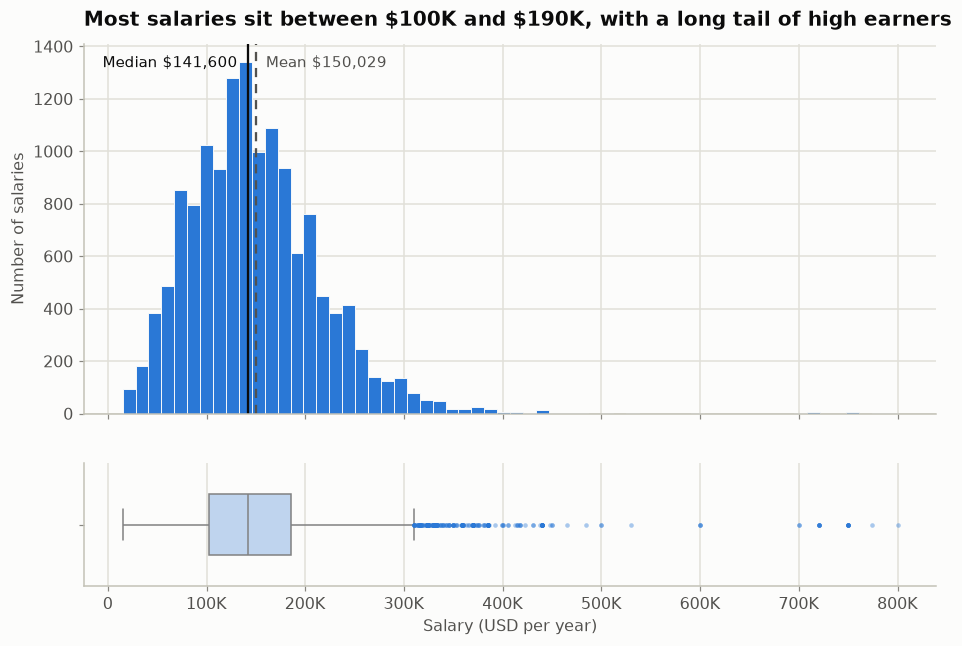

Middle 50% of salaries: $103,000 to $185,900 | skewness 1.49


In [28]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.4), height_ratios=[3, 1], sharex=True)
ax1.hist(df.salary_in_usd, bins=60, color=S.BLUE, edgecolor=S.SURFACE, linewidth=0.6)
med, mean = df.salary_in_usd.median(), df.salary_in_usd.mean()
ax1.axvline(med, color=S.INK, lw=1.5)
ax1.axvline(mean, color=S.INK_SECONDARY, lw=1.5, ls=(0, (4, 3)))
ax1.text(med, ax1.get_ylim()[1] * 0.97, f"Median {usd(med)}  ", color=S.INK, va="top", ha="right", fontsize=10)
ax1.text(mean, ax1.get_ylim()[1] * 0.97, f"  Mean {usd(mean)}", color=S.INK_SECONDARY, va="top", ha="left", fontsize=10)
ax1.set_ylabel("Number of salaries")
ax1.set_title("Most salaries sit between $100K and $190K, with a long tail of high earners")
sns.boxplot(x=df.salary_in_usd, ax=ax2, color="#b7d3f6", width=0.5, linewidth=1,
            flierprops=dict(marker="o", markersize=3, markerfacecolor=S.BLUE, markeredgecolor="none", alpha=0.4))
ax2.set_xlabel("Salary (USD per year)")
ax2.xaxis.set_major_formatter(K)
ax2.grid(axis="y", visible=False)
save(fig, "01_salary_distribution")
q1, q3 = df.salary_in_usd.quantile([0.25, 0.75])
print(f"Middle 50% of salaries: {usd(q1)} to {usd(q3)} | skewness {df.salary_in_usd.skew():.2f}")

**Insight:** half of all salaries are between **$103,000 and $185,900** per year. The distribution is right-skewed (skewness 1.49): most people earn around the middle, while a small group earns much more and pulls the mean ($150,029) above the median ($141,600). That is why the charts below use the median.

### Chart 2: Where does the data come from?

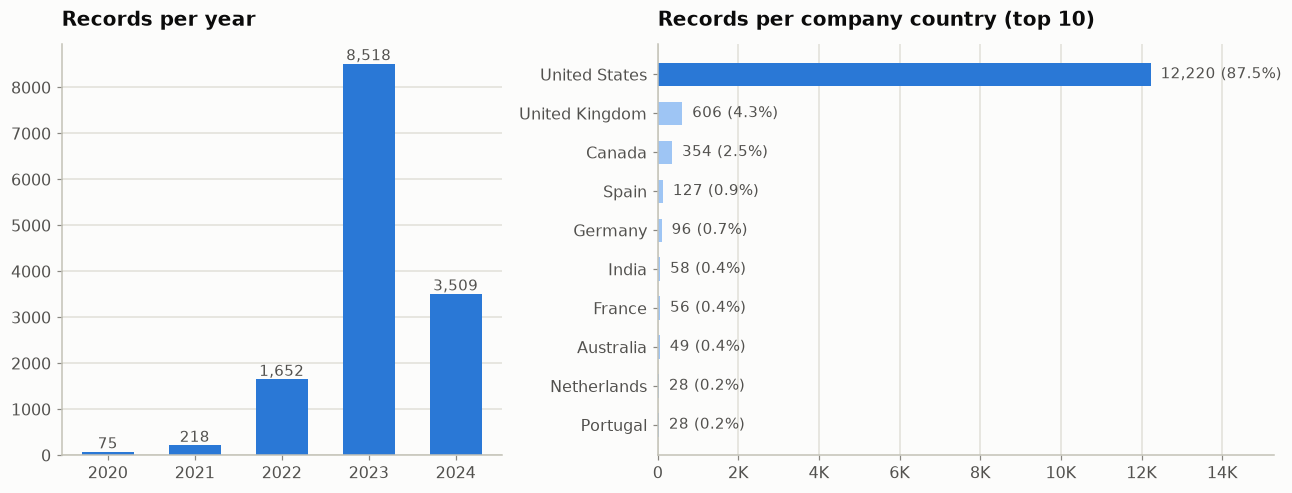

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6), width_ratios=[1, 1.4])
by_year = df.work_year.value_counts().sort_index()
ax1.bar(by_year.index.astype(str), by_year.values, color=S.BLUE, width=0.6)
for x, v in zip(by_year.index.astype(str), by_year.values):
    ax1.text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=9.5, color=S.INK_SECONDARY)
ax1.set_title("Records per year")
ax1.grid(axis="x", visible=False)

top_c = df.company_country.value_counts().head(10).sort_values()
colors = [S.BLUE if c == "United States" else "#9ec5f4" for c in top_c.index]
ax2.barh(top_c.index, top_c.values, color=colors, height=0.6)
for y, v in enumerate(top_c.values):
    ax2.text(v, y, f"  {v:,} ({v / len(df):.1%})", va="center", fontsize=9.5, color=S.INK_SECONDARY)
ax2.set_title("Records per company country (top 10)")
ax2.set_xlim(0, top_c.max() * 1.25)
ax2.grid(axis="y", visible=False)
ax2.xaxis.set_major_formatter(K)
fig.tight_layout()
save(fig, "02_data_composition")

**Insight:** the data is concentrated in 2023 and in the United States (87.5% of records). Statements about other countries rest on far fewer records, so country results outside the US should be read with care.

### Chart 3: Who is in the data? (categorical variables)

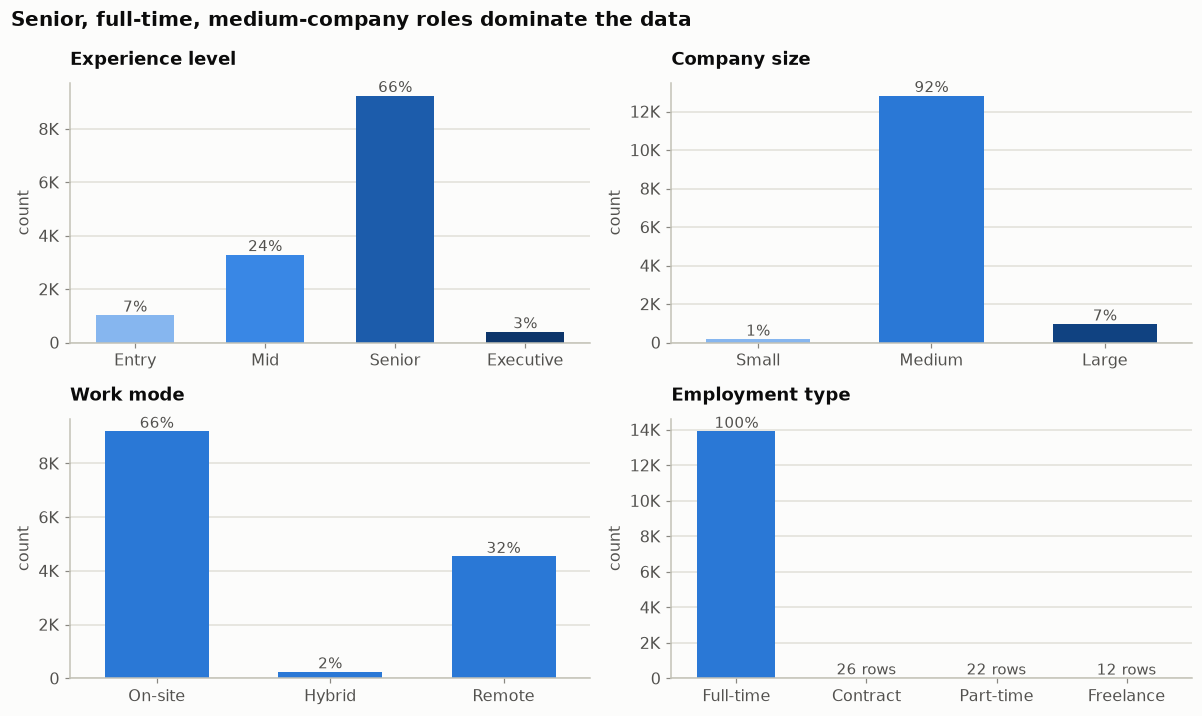

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.6))
specs = [
    ("experience_label", F.EXPERIENCE_ORDER, S.RAMP_4, "Experience level"),
    ("company_size_label", F.COMPANY_SIZE_ORDER, S.RAMP_3, "Company size"),
    ("work_mode", F.WORK_MODE_ORDER, [S.BLUE] * 3, "Work mode"),
    ("employment_label", ["Full-time", "Contract", "Part-time", "Freelance"], [S.BLUE] * 4, "Employment type"),
]
for ax, (col, order, colors, title) in zip(axes.flat, specs):
    counts = df[col].value_counts().reindex(order)
    sns.countplot(data=df, x=col, order=order, hue=col, hue_order=order, palette=colors, legend=False,
                  width=0.6, dodge=False, saturation=1, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel("count")
    for x, v in zip(order, counts.values):
        label = f"{v / len(df):.0%}" if v / len(df) >= 0.01 else f"{v} rows"
        ax.text(x, v, label, ha="center", va="bottom", fontsize=9.5, color=S.INK_SECONDARY)
    ax.set_title(title, fontsize=12)
    ax.yaxis.set_major_formatter(K)
    ax.grid(axis="x", visible=False)
fig.suptitle("Senior, full-time, medium-company roles dominate the data", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "03_categorical_counts")

**Insight:** two out of three records are Senior level, and almost all are full-time at medium-size companies. Hybrid work (2%), small companies (1%) and non-full-time contracts (60 rows in total) are rare, so conclusions about them rest on small groups.

## 5. Bivariate analysis (how each factor relates to salary)

Three kinds of relationships, each with its own tools (Unit 3, Part 4):

| Relationship | Example here | Tools used |
|---|---|---|
| Categorical vs numerical | experience level vs salary | groupby mean/median, bar charts, boxplots by category |
| Numerical vs numerical | experience rank, company size rank, year vs salary | correlation matrix, scatter plot |
| Categorical vs categorical | work mode vs company location | crosstab, countplot with hue |

We mostly use the **median** (middle value) rather than the mean, because a few very high salaries pull the mean up.

### 5.1 Groupby: mean vs median salary by experience

In [31]:
group_stats = (df.groupby("experience_label", observed=True).salary_in_usd
               .agg(count="size", mean="mean", median="median").reindex(F.EXPERIENCE_ORDER))
group_stats["mean minus median"] = group_stats["mean"] - group_stats["median"]
group_stats.round(0)

,count,mean,median,mean minus median
experience_label,,,,
Entry,1027,"91,182.00","82,000.00","9,182.00"
Mid,3294,"125,056.00","113,250.00","11,806.00"
Senior,9248,"163,579.00","155,000.00","8,579.00"
Executive,403,"193,153.00","190,000.00","3,153.00"


**What we see and why it matters:** for every level the mean is higher than the median, by $3,000 to $12,000, because a few very high salaries pull the mean up. The ranking is the same with either measure, but the median describes the typical person better, so the charts use it.

### 5.2 Categorical vs numerical charts

### Chart 4: Salary by experience level

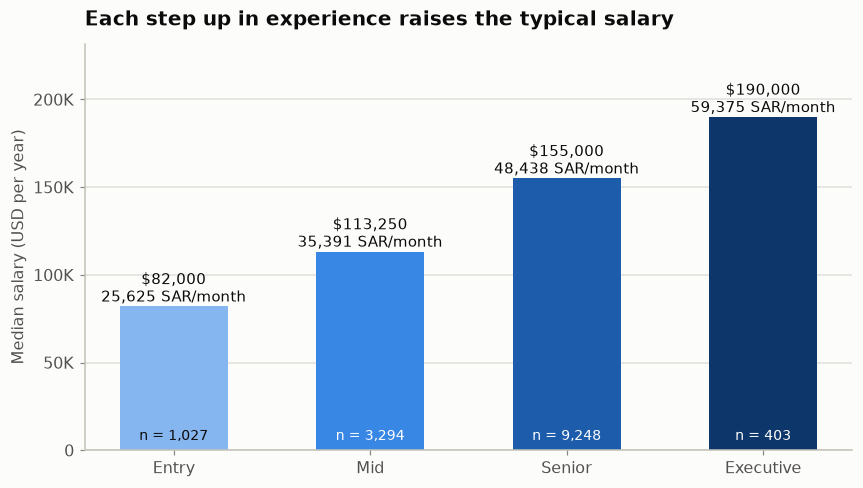

Increase at each step: Entry to Mid: +38%, Mid to Senior: +37%, Senior to Executive: +23%
Executive vs Entry: x2.32


In [32]:
exp = df.groupby("experience_label", observed=True).salary_in_usd.agg(["median", "size"]).reindex(F.EXPERIENCE_ORDER)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(exp.index, exp["median"], color=S.RAMP_4, width=0.55)
for i, (x, (m, n)) in enumerate(zip(exp.index, exp.values)):
    ax.text(x, m, f"{usd(m)}\n{m * F.USD_TO_SAR / 12:,.0f} SAR/month", ha="center", va="bottom", fontsize=9.5)
    ax.text(x, 4000, f"n = {int(n):,}", ha="center", va="bottom", fontsize=9, color=S.INK if i == 0 else "white")
ax.set_ylim(0, exp["median"].max() * 1.22)
ax.yaxis.set_major_formatter(K)
ax.set_ylabel("Median salary (USD per year)")
ax.set_title("Each step up in experience raises the typical salary")
ax.grid(axis="x", visible=False)
save(fig, "04_salary_by_experience")
steps = exp["median"].pct_change().dropna()
print("Increase at each step:", ", ".join(f"{a} to {b}: +{v:.0%}" for (a, b), v in zip(zip(exp.index[:-1], exp.index[1:]), steps)))
print(f"Executive vs Entry: x{exp['median'].iloc[-1] / exp['median'].iloc[0]:.2f}")

**Insight:** experience is one of the clearest salary drivers. The typical salary rises by **38%** from Entry to Mid, **37%** from Mid to Senior and **23%** from Senior to Executive. An Executive earns about **2.3 times** an Entry-level employee ($190,000 vs $82,000 per year, about 59,400 vs 25,600 SAR per month).

### Chart 5: Salary by job family

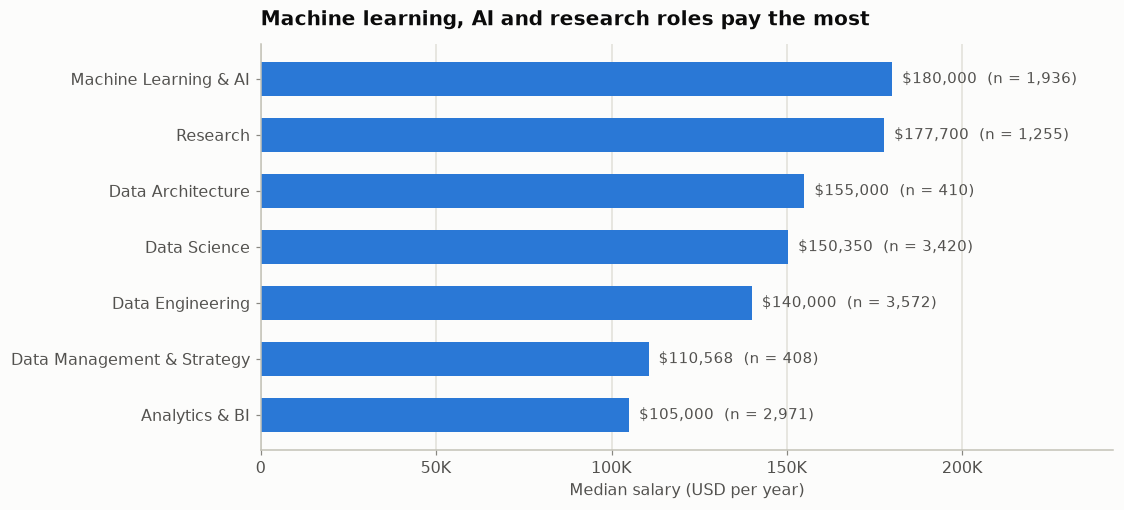

In [33]:
fam = (df.groupby("job_family").salary_in_usd.agg(["median", "size"]).sort_values("median"))
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(fam.index, fam["median"], color=S.BLUE, height=0.6)
for y, (m, n) in enumerate(fam.values):
    ax.text(m, y, f"  {usd(m)}  (n = {int(n):,})", va="center", fontsize=9.5, color=S.INK_SECONDARY)
ax.set_xlim(0, fam["median"].max() * 1.35)
ax.xaxis.set_major_formatter(K)
ax.set_xlabel("Median salary (USD per year)")
ax.set_title("Machine learning, AI and research roles pay the most")
ax.grid(axis="y", visible=False)
save(fig, "05_salary_by_job_family")

**Insight:** Machine Learning & AI ($180,000) and Research ($177,700) pay the most, while Analytics & BI pays the least ($105,000). The top family earns about 70% more than the bottom one, so the *type* of data work matters a lot.

### Chart 6: The highest and lowest paid job titles

Only titles with at least 30 records, so a single unusual salary cannot drive the result.

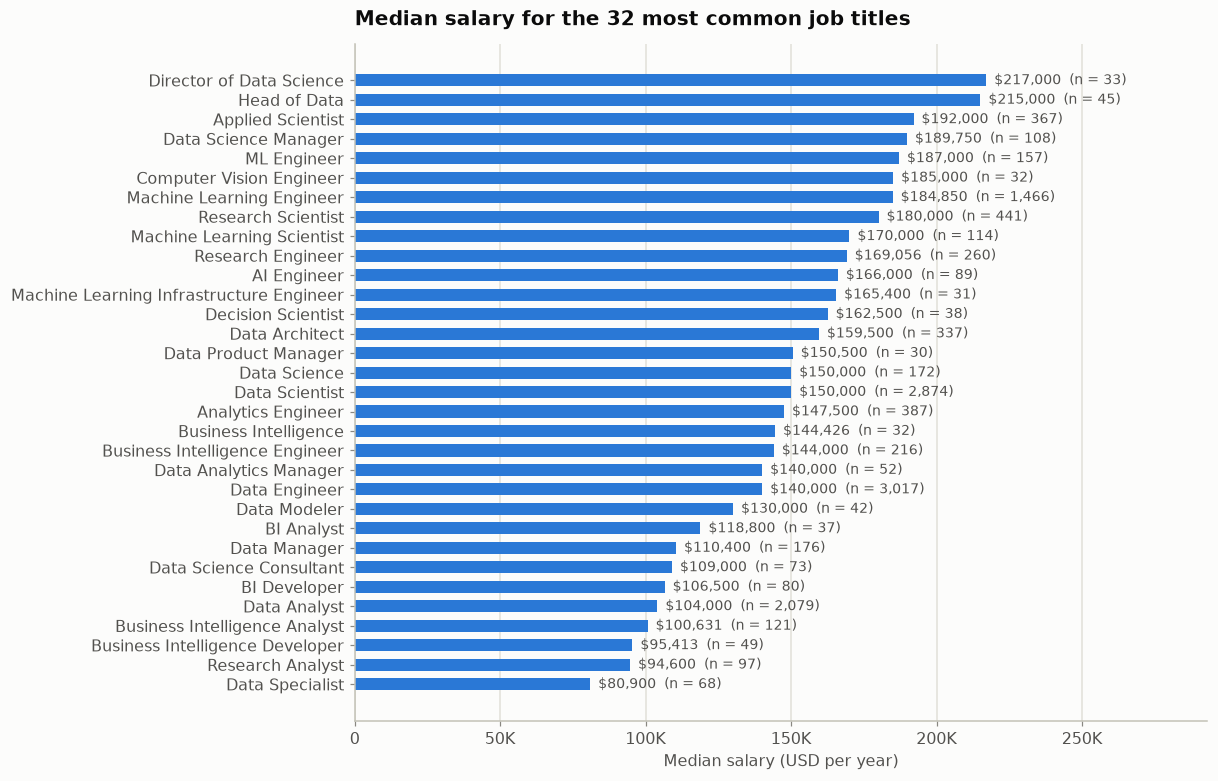

In [34]:
title_stats = df.groupby("job_title").salary_in_usd.agg(["median", "size"])
title_stats = title_stats[title_stats["size"] >= 30].sort_values("median")
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(title_stats.index, title_stats["median"], color=S.BLUE, height=0.62)
for y, (m, n) in enumerate(title_stats.values):
    ax.text(m, y, f"  {usd(m)}  (n = {int(n):,})", va="center", fontsize=9, color=S.INK_SECONDARY)
ax.set_xlim(0, title_stats["median"].max() * 1.35)
ax.xaxis.set_major_formatter(K)
ax.set_xlabel("Median salary (USD per year)")
ax.set_title(f"Median salary for the {len(title_stats)} most common job titles")
ax.grid(axis="y", visible=False)
save(fig, "06_salary_by_job_title")

**Insight:** leadership titles (Director of Data Science $217,000, Head of Data $215,000) and specialised ML and research roles (Applied Scientist $192,000, ML Engineer $187,000) are at the top. Analyst, BI developer and specialist roles are at the bottom ($80,900 to $106,500). "Data Scientist" and "Data Science" have the same median ($150,000), which suggests they are the same job written two ways.

### Chart 7: Salary by company country

Countries with at least 20 records.

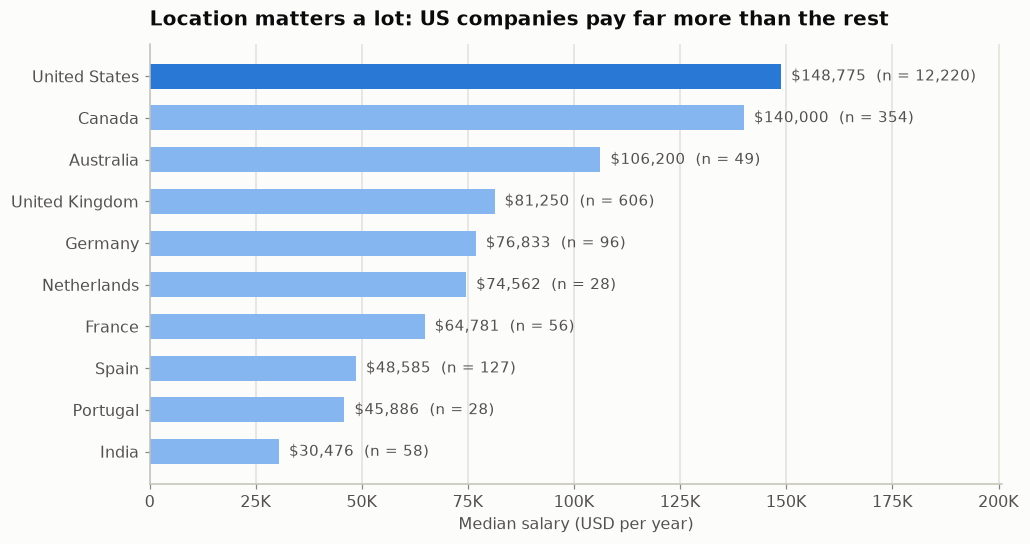

US median $148,775 vs rest of world $79,833 (x1.86)


In [35]:
ctry = df.groupby("company_country").salary_in_usd.agg(["median", "size"])
ctry = ctry[ctry["size"] >= 20].sort_values("median")
fig, ax = plt.subplots(figsize=(10, 5.2))
colors = [S.BLUE if c == "United States" else "#86b6ef" for c in ctry.index]
ax.barh(ctry.index, ctry["median"], color=colors, height=0.6)
for y, (m, n) in enumerate(ctry.values):
    ax.text(m, y, f"  {usd(m)}  (n = {int(n):,})", va="center", fontsize=9.5, color=S.INK_SECONDARY)
ax.set_xlim(0, ctry["median"].max() * 1.35)
ax.xaxis.set_major_formatter(K)
ax.set_xlabel("Median salary (USD per year)")
ax.set_title("Location matters a lot: US companies pay far more than the rest")
ax.grid(axis="y", visible=False)
save(fig, "07_salary_by_country")
us_med = df.loc[df.is_us == 1, "salary_in_usd"].median()
non_us_med = df.loc[df.is_us == 0, "salary_in_usd"].median()
print(f"US median {usd(us_med)} vs rest of world {usd(non_us_med)} (x{us_med / non_us_med:.2f})")

**Insight:** company location is a major factor. US companies pay a median of **$148,775**, about **1.9 times** the rest of the world ($79,833). Canada is close to the US, Western Europe sits in the middle, and India has the lowest median among countries with enough records ($30,476).

### Chart 8: How salaries changed over time

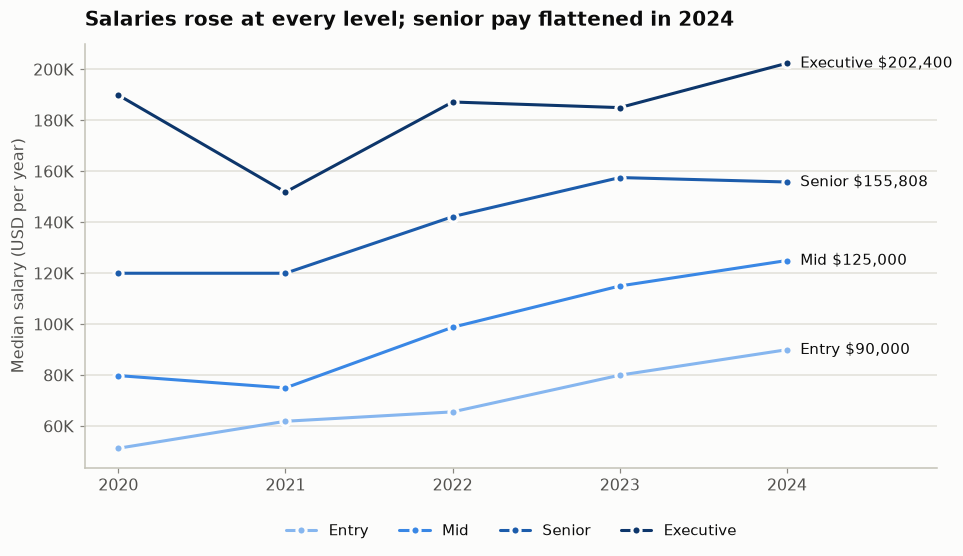

Records per year and level (small early samples are less reliable):


experience_label,Entry,Mid,Senior,Executive
work_year,,,,
2020,21,31,19,4
2021,46,87,75,10
2022,116,358,1137,41
2023,463,1716,6097,242
2024,381,1102,1920,106


In [36]:
trend = df.pivot_table(index="work_year", columns="experience_label", values="salary_in_usd",
                       aggfunc="median", observed=True)[F.EXPERIENCE_ORDER]
counts = df.pivot_table(index="work_year", columns="experience_label", values="salary_in_usd",
                        aggfunc="size", observed=True)[F.EXPERIENCE_ORDER]
fig, ax = plt.subplots(figsize=(10, 5))
for level, color in zip(F.EXPERIENCE_ORDER, S.RAMP_4):
    ax.plot(trend.index, trend[level], color=color, marker="o", markersize=6,
            markeredgecolor=S.SURFACE, markeredgewidth=2, label=level)
    ax.text(trend.index[-1] + 0.08, trend[level].iloc[-1], f"{level} {usd(trend[level].iloc[-1])}",
            va="center", fontsize=9.5, color=S.INK)
ax.set_xticks(trend.index)
ax.set_xlim(trend.index.min() - 0.2, trend.index.max() + 0.9)
ax.yaxis.set_major_formatter(K)
ax.set_ylabel("Median salary (USD per year)")
ax.set_title("Salaries rose at every level; senior pay flattened in 2024")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4)
ax.grid(axis="x", visible=False)
save(fig, "08_salary_trend")
print("Records per year and level (small early samples are less reliable):")
counts

**Insight:** salaries rose at every level between 2021 and 2023, with the biggest jump in 2022. In 2024, Entry ($90,000) and Mid ($125,000) salaries kept rising while Senior salaries flattened ($155,808). The 2020 and 2021 points, and the Executive line in every year, are based on few records, so their ups and downs are not reliable.

### Chart 9: Remote, hybrid or on-site?

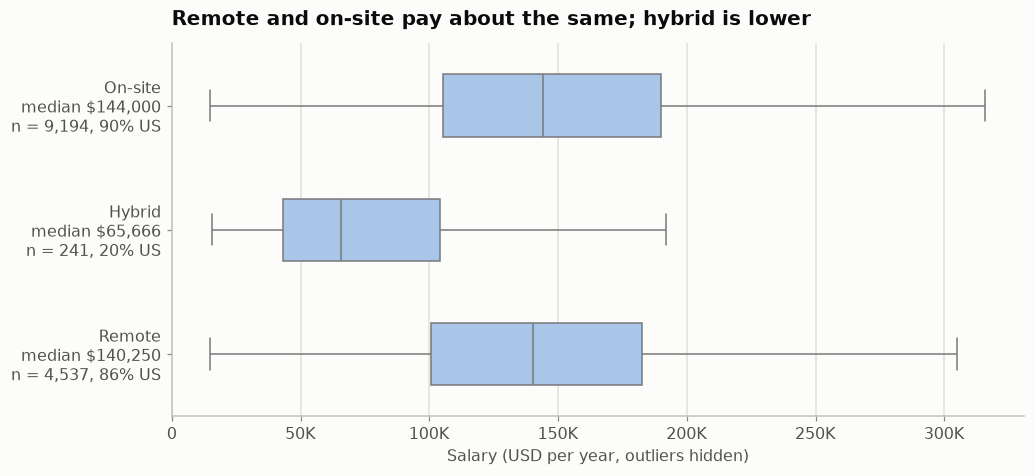

,median,n,us_share
work_mode,,,
On-site,"144,000.00",9194,0.90
Hybrid,"65,666.00",241,0.20
Remote,"140,250.00",4537,0.86


In [37]:
fig, ax = plt.subplots(figsize=(10, 4.4))
sns.boxplot(data=df, y="work_mode", x="salary_in_usd", order=F.WORK_MODE_ORDER, ax=ax,
            color="#9ec5f4", width=0.5, linewidth=1, showfliers=False)
wm = df.groupby("work_mode", observed=True).agg(median=("salary_in_usd", "median"), n=("salary_in_usd", "size"),
                                               us_share=("is_us", "mean")).reindex(F.WORK_MODE_ORDER)
ax.set_yticks(range(3), [f"{mode}\nmedian {usd(m)}\nn = {int(n):,}, {us:.0%} US" for mode, (m, n, us)
                         in zip(wm.index, wm.values)])
ax.xaxis.set_major_formatter(K)
ax.set_xlabel("Salary (USD per year, outliers hidden)")
ax.set_ylabel("")
ax.set_title("Remote and on-site pay about the same; hybrid is lower")
save(fig, "09_salary_by_work_mode")
wm

**Insight:** remote ($140,250) and on-site ($144,000) salaries are almost the same. Hybrid roles look much lower ($65,666), but only 20% of hybrid records are from US companies, compared with 86% to 90% for the others. The lower hybrid pay is mostly a **location effect**, not a work-mode effect. A relationship between two variables can be caused by a third one.

### Chart 10: Company size

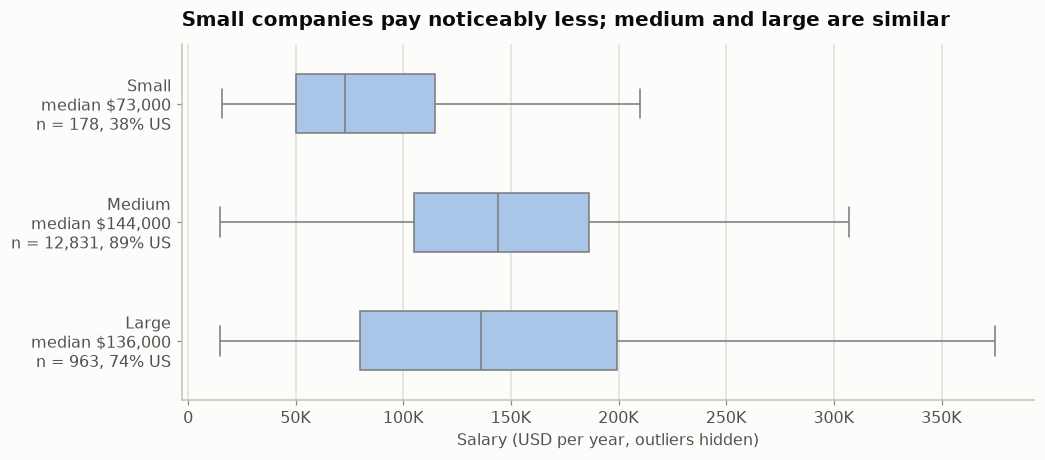

,median,n,us_share
company_size_label,,,
Small,"73,000.00",178,0.38
Medium,"144,000.00",12831,0.89
Large,"136,000.00",963,0.74


In [38]:
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.boxplot(data=df, y="company_size_label", x="salary_in_usd", order=F.COMPANY_SIZE_ORDER, ax=ax,
            color="#9ec5f4", width=0.5, linewidth=1, showfliers=False)
cs = df.groupby("company_size_label", observed=True).agg(median=("salary_in_usd", "median"),
                                                        n=("salary_in_usd", "size"),
                                                        us_share=("is_us", "mean")).reindex(F.COMPANY_SIZE_ORDER)
ax.set_yticks(range(3), [f"{size}\nmedian {usd(m)}\nn = {int(n):,}, {us:.0%} US" for size, (m, n, us)
                         in zip(cs.index, cs.values)])
ax.xaxis.set_major_formatter(K)
ax.set_xlabel("Salary (USD per year, outliers hidden)")
ax.set_ylabel("")
ax.set_title("Small companies pay noticeably less; medium and large are similar")
save(fig, "10_salary_by_company_size")
cs

**Insight:** small companies have a much lower median ($73,000) than medium ($144,000) and large ($136,000) companies, and medium and large are similar. As with hybrid work, location plays a role: only 38% of small-company records are from the US.

### Chart 11: Experience and job family together

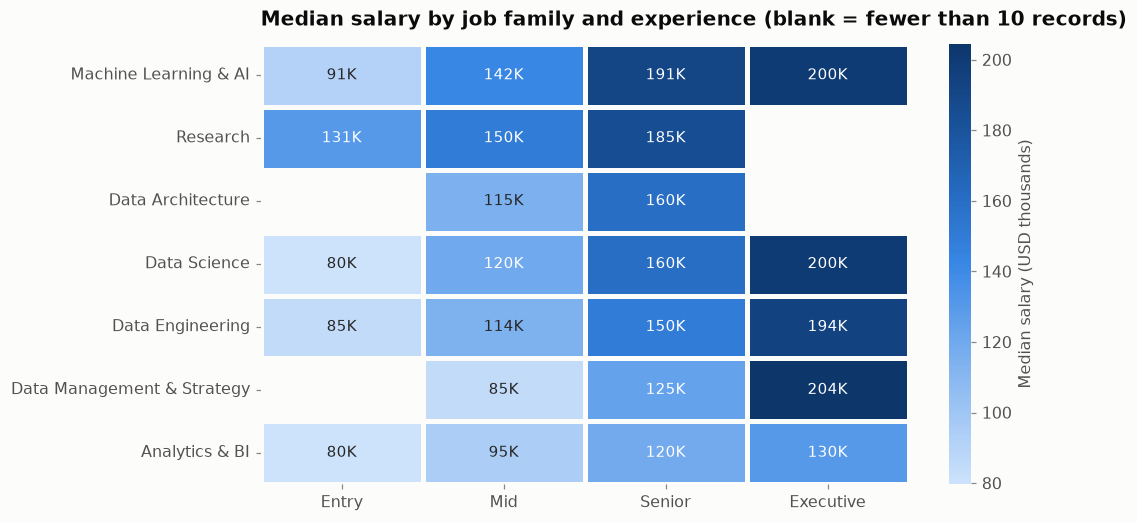

In [39]:
heat = df.pivot_table(index="job_family", columns="experience_label", values="salary_in_usd",
                      aggfunc="median", observed=True)[F.EXPERIENCE_ORDER]
heat_n = df.pivot_table(index="job_family", columns="experience_label", values="salary_in_usd",
                        aggfunc="size", observed=True)[F.EXPERIENCE_ORDER]
heat = heat.where(heat_n >= 10).loc[fam.index[::-1]]
fig, ax = plt.subplots(figsize=(9.5, 5.2))
cmap = sns.blend_palette(S.SEQUENTIAL, as_cmap=True)
sns.heatmap(heat / 1000, annot=True, fmt=".0f", cmap=cmap, linewidths=2, linecolor=S.SURFACE,
            cbar_kws={"label": "Median salary (USD thousands)"}, ax=ax, annot_kws={"fontsize": 10})
for text in ax.texts:
    text.set_text(f"{text.get_text()}K")
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("Median salary by job family and experience (blank = fewer than 10 records)")
ax.grid(False)
save(fig, "11_heatmap_family_experience")

**Insight:** the experience effect appears in every job family, and the gap between families grows with seniority. At Entry level most families start between $80K and $91K (Research is the exception at $131K), while at Senior level the range widens from $120K (Analytics & BI) to $191K (Machine Learning & AI).

### Chart 12: Which factors relate most to salary?

For categorical factors we use the **correlation ratio (eta)**: how much of the salary variation is explained by knowing the group. 0 = nothing, 1 = everything.

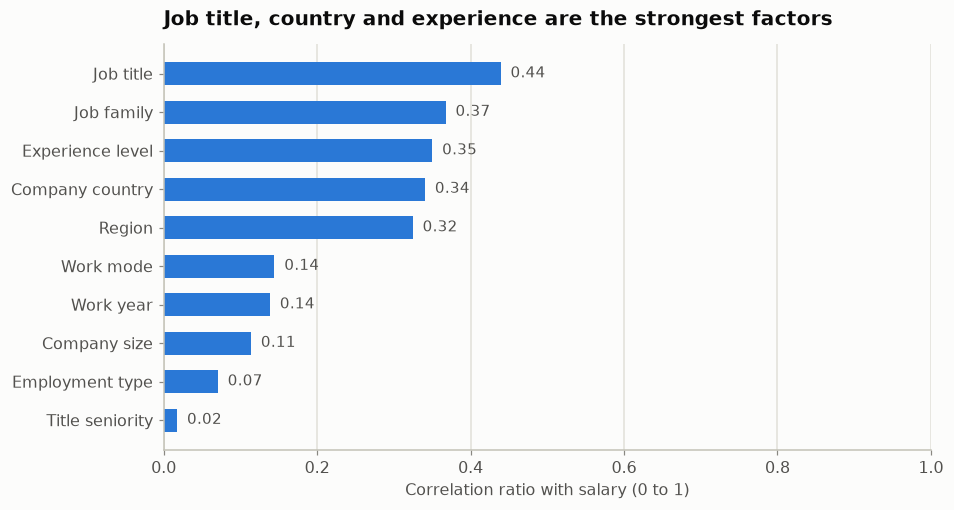

In [40]:
def correlation_ratio(categories, values):
    cats = pd.Series(categories).astype(str).values
    values = np.asarray(values, dtype=float)
    grand = values.mean()
    between = sum(values[cats == c].size * (values[cats == c].mean() - grand) ** 2 for c in np.unique(cats))
    total = ((values - grand) ** 2).sum()
    return float(np.sqrt(between / total))

factor_cols = {"Job title": "job_title", "Company country": "company_country", "Experience level": "experience_label",
               "Job family": "job_family", "Region": "region", "Work year": "work_year",
               "Company size": "company_size_label", "Work mode": "work_mode", "Employment type": "employment_label",
               "Title seniority": "title_seniority"}
eta = pd.Series({name: correlation_ratio(df[col], df.salary_in_usd) for name, col in factor_cols.items()}).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(eta.index, eta.values, color=S.BLUE, height=0.6)
for y, v in enumerate(eta.values):
    ax.text(v, y, f"  {v:.2f}", va="center", fontsize=9.5, color=S.INK_SECONDARY)
ax.set_xlim(0, 1)
ax.set_xlabel("Correlation ratio with salary (0 to 1)")
ax.set_title("Job title, country and experience are the strongest factors")
ax.grid(axis="y", visible=False)
save(fig, "12_factor_strength")

**Insight:** on its own, job title explains the most salary variation (0.44), followed by job family (0.37), experience (0.35) and company country (0.34). Work mode, year, company size and employment type have much weaker links. Even the strongest factor is far from 1, an early hint that a model built on these columns will explain only part of the salary differences.

### 5.3 Numerical vs numerical

### Chart 13: Correlation matrix

Spearman correlation (works for ordered values such as ranks). Values go from -1 (strong negative) through 0 (no relationship) to +1 (strong positive).

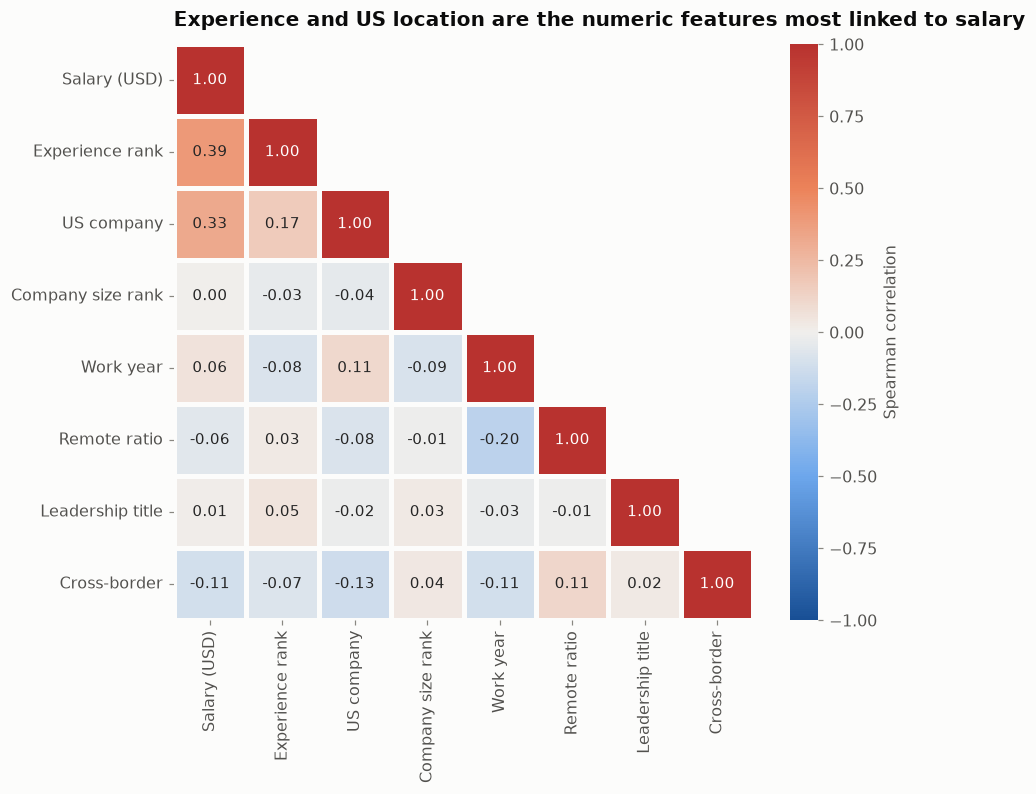

,correlation with salary
Experience rank,0.39
US company,0.33
Cross-border,-0.11
Work year,0.06
Remote ratio,-0.06
Leadership title,0.01
Company size rank,0.00


In [41]:
corr_cols = {"salary_in_usd": "Salary (USD)", "experience_rank": "Experience rank", "is_us": "US company",
             "company_size_rank": "Company size rank", "work_year": "Work year", "remote_ratio": "Remote ratio",
             "is_management": "Leadership title", "cross_border": "Cross-border"}
corr = df[list(corr_cols)].rename(columns=corr_cols).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 6.8))
diverging = sns.blend_palette(["#184f95", "#6da7ec", "#f0efec", "#ec835a", "#b8322f"], as_cmap=True)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=diverging, vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor=S.SURFACE, cbar_kws={"label": "Spearman correlation"}, ax=ax,
            annot_kws={"fontsize": 9.5})
ax.set_title("Experience and US location are the numeric features most linked to salary")
ax.grid(False)
save(fig, "13_correlation_matrix")
corr["Salary (USD)"].drop("Salary (USD)").sort_values(key=abs, ascending=False).round(3).to_frame("correlation with salary")

**What we see and why it matters**

* Experience rank (0.39) and being at a US company (0.33) have the strongest positive relationship with salary.
* Cross-border work is slightly negative (-0.11); year, remote ratio, leadership title and company size rank are close to 0.
* The features are only weakly correlated with each other (at most 0.20 in absolute value), so they bring mostly separate information.
* A near-zero correlation does not always mean no effect: company size is almost constant (92% Medium) and only 4% of titles are leadership titles, so there is little variation to measure.

### Chart 14: Scatter plot, local salary vs salary in USD (why `salary` is leakage)

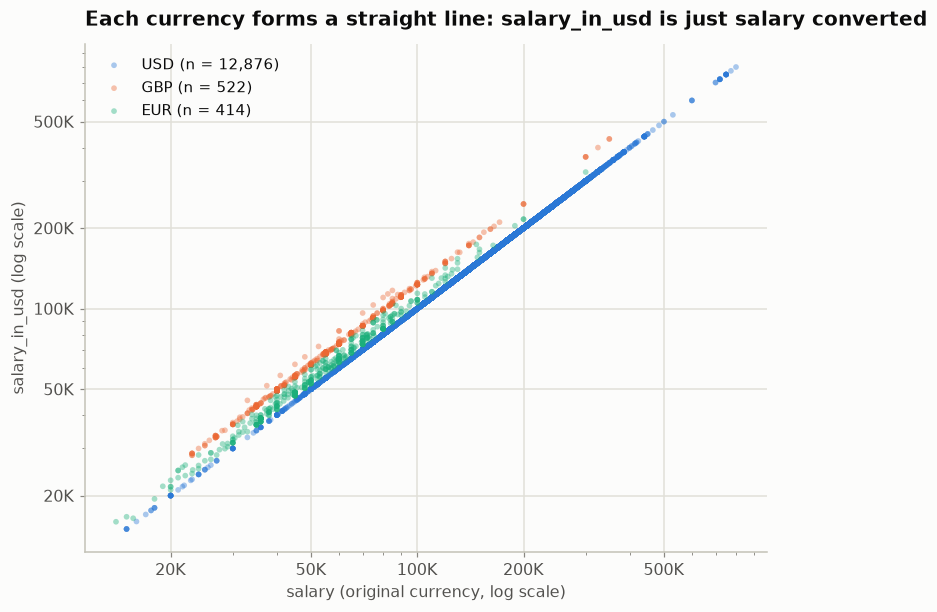

Pearson correlation between salary and salary_in_usd for USD rows: 1.0


In [42]:
cur = df[df.salary_currency.isin(["USD", "GBP", "EUR"])]
fig, ax = plt.subplots(figsize=(8, 6))
for currency, color in zip(["USD", "GBP", "EUR"], [S.BLUE, S.ORANGE, S.CATEGORICAL[2]]):
    sub = cur[cur.salary_currency == currency]
    ax.scatter(sub.salary, sub.salary_in_usd, s=14, alpha=0.4, color=color, edgecolor="none",
               label=f"{currency} (n = {len(sub):,})")
ax.set_xscale("log")
ax.set_yscale("log")
log_ticks = [20_000, 50_000, 100_000, 200_000, 500_000]
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_locator(mticker.FixedLocator(log_ticks))
    axis.set_major_formatter(K)
    axis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlabel("salary (original currency, log scale)")
ax.set_ylabel("salary_in_usd (log scale)")
ax.set_title("Each currency forms a straight line: salary_in_usd is just salary converted")
ax.legend(loc="upper left")
save(fig, "14_salary_vs_salary_in_usd")
print("Pearson correlation between salary and salary_in_usd for USD rows:",
      round(cur[cur.salary_currency == "USD"][["salary", "salary_in_usd"]].corr().iloc[0, 1], 3))

**What we see and why it matters:** for USD rows the two columns are identical (correlation 1.0), and GBP and EUR rows form their own straight lines (just the exchange rate). `salary_in_usd` is a direct conversion of `salary`, so giving `salary` to the model would hand it the answer. This is **data leakage**, and it is why `salary` and `salary_currency` are excluded from the model.

### 5.4 Categorical vs categorical

### Chart 15: Work mode by company location (crosstab and countplot with hue)

Why were hybrid salaries so low in Chart 9? A crosstab checks whether hybrid jobs are spread evenly across locations.

Share of each work mode by company location:
location_group Non-US company US company
work_mode                               
On-site                   10%        90%
Hybrid                    80%        20%
Remote                    14%        86%


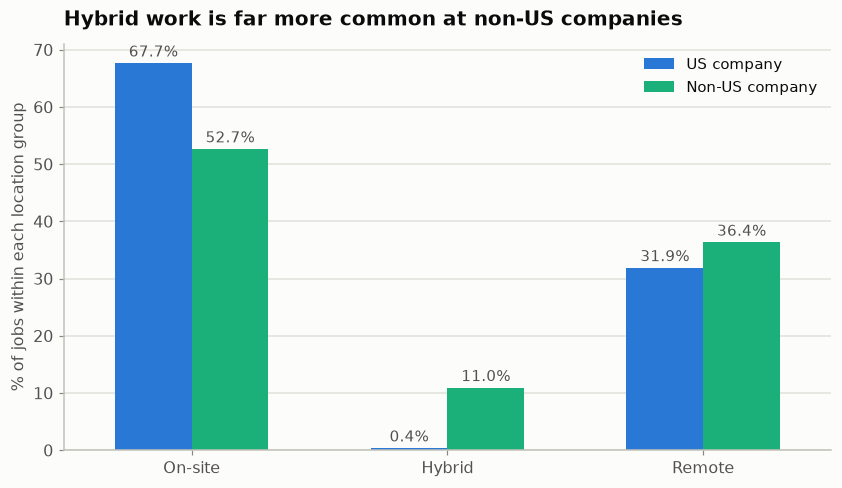

location_group,Non-US company,US company,All
work_mode,,,
On-site,923,8271,9194
Hybrid,192,49,241
Remote,637,3900,4537
All,1752,12220,13972


In [43]:
df["location_group"] = np.where(df.is_us == 1, "US company", "Non-US company")
ct = pd.crosstab(df.work_mode, df.location_group, normalize="index").reindex(F.WORK_MODE_ORDER)
print("Share of each work mode by company location:")
print(ct.map("{:.0%}".format).to_string())

fig, ax = plt.subplots(figsize=(9, 4.8))
# Countplot with hue, shown as % within each location group so the smaller non-US group stays visible
shares = (pd.crosstab(df.work_mode, df.location_group, normalize="columns") * 100).reindex(F.WORK_MODE_ORDER)
shares_long = shares.reset_index().melt(id_vars="work_mode", var_name="location_group", value_name="percent")
sns.barplot(data=shares_long, x="work_mode", y="percent", order=F.WORK_MODE_ORDER, hue="location_group",
            hue_order=["US company", "Non-US company"],
            palette={"US company": S.BLUE, "Non-US company": S.CATEGORICAL[2]}, width=0.6, saturation=1, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=2, fontsize=9.5, color=S.INK_SECONDARY)
ax.set_ylabel("% of jobs within each location group")
ax.set_xlabel("")
ax.set_title("Hybrid work is far more common at non-US companies")
ax.grid(axis="x", visible=False)
ax.legend(title="", loc="upper right")
save(fig, "15_work_mode_by_location")
pd.crosstab(df.work_mode, df.location_group, margins=True).reindex(F.WORK_MODE_ORDER + ["All"])

**What we see and why it matters:** only **0.4%** of jobs at US companies are hybrid, compared with **11.0%** at non-US companies, and 80% of all hybrid jobs are at non-US companies. Non-US companies pay less in this data, so hybrid jobs look lower paid. Location is a **confounder**: it explains the hybrid gap from Chart 9, not the work mode itself.

### 5.5 Reading relationships correctly

* **Correlation is not causation.** Hybrid work does not *cause* lower pay; hybrid jobs are simply more common outside the US.
* **Sample size matters.** Groups with few records (Executive in 2020, small companies, hybrid work) move a lot by chance.
* **Strongest candidates for the model:** job title and family, company country, and experience level. Work mode, company size and employment type show weaker or indirect links.

## 6. Saudi Arabia in a global context

The dataset has only **2** records from Saudi companies, so it cannot describe the Saudi market.
To make the comparison global, we collected real published Saudi salary figures for the same roles from external sources (`data/saudi_benchmark.csv`).

**Important:** these figures are kept as a **separate benchmark** and are **not** mixed into the training data, because they were measured differently:

* Recruiter surveys (Robert Walters) report **basic salary**, which in Saudi Arabia usually excludes allowances (such as housing and transport) and bonuses, so total pay is higher.
* Crowd-sourced sites (Levels.fyi, Glassdoor, Paylab, PayScale) report total pay from small samples.
* They cover 2024 to 2026, while the dataset covers 2020 to 2024.

In [44]:
bench = F.load_saudi_benchmark()
bench[["source", "source_type", "role", "pay_basis", "min_sar_month", "mid_sar_month", "max_sar_month",
       "range_definition", "sample_note"]]

,source,source_type,role,pay_basis,min_sar_month,mid_sar_month,max_sar_month,range_definition,sample_note
0,Robert Walters 2025 Salary Survey,Recruiter survey,Data Analyst,Basic salary (excludes allowances and bonus),"20,000.00","30,000.00","40,000.00",Lower to upper limit,Based on 100k+ roles advertised in the Middle ...
1,Robert Walters 2025 Salary Survey,Recruiter survey,Data Scientist,Basic salary (excludes allowances and bonus),"30,000.00","35,000.00","40,000.00",Lower to upper limit,Based on 100k+ roles advertised in the Middle ...
2,Robert Walters 2025 Salary Survey,Recruiter survey,Head of Data Analytics,Basic salary (excludes allowances and bonus),"60,000.00","70,000.00","80,000.00",Lower to upper limit,Based on 100k+ roles advertised in the Middle ...
3,Robert Walters 2025 Salary Survey,Recruiter survey,Head of Machine Learning,Basic salary (excludes allowances and bonus),"80,000.00","95,000.00","110,000.00",Lower to upper limit,Based on 100k+ roles advertised in the Middle ...
4,Robert Walters 2025 Salary Survey,Recruiter survey,Head of AI,Basic salary (excludes allowances and bonus),"80,000.00","100,000.00","120,000.00",Lower to upper limit,Based on 100k+ roles advertised in the Middle ...
5,Robert Walters 2025 Salary Survey,Recruiter survey,Chief Data Officer,Basic salary (excludes allowances and bonus),"65,000.00","85,000.00","105,000.00",Lower to upper limit,Based on 100k+ roles advertised in the Middle ...
6,Levels.fyi,Crowd-sourced,Data Scientist,Total compensation,"25,000.00","28,975.00","35,000.00",25th to 75th percentile,10 reported salaries
7,Glassdoor (Riyadh),Crowd-sourced,Data Scientist,Total pay,"14,000.00","17,000.00","27,000.00",Reported range,About 50 reported salaries (page may include o...
8,Paylab,Crowd-sourced,Data Scientist,Gross monthly salary,"7,198.00",NaN,"29,323.00",10th to 90th percentile,Fewer than 20 verified respondents
9,ZenHR Salary Guide,HR platform guide,Data Analyst,Gross monthly salary,"10,000.00","15,000.00","22,000.00",Minimum to maximum,ZenHR market data and public labour surveys


### Chart 16: Data Scientist and Data Analyst monthly pay, Saudi Arabia vs other countries

Dataset countries show the middle 50% of salaries (25th to 75th percentile) with the median as a dot, converted to SAR per month.
Saudi sources show the range each source publishes, with its average or median as a dot.

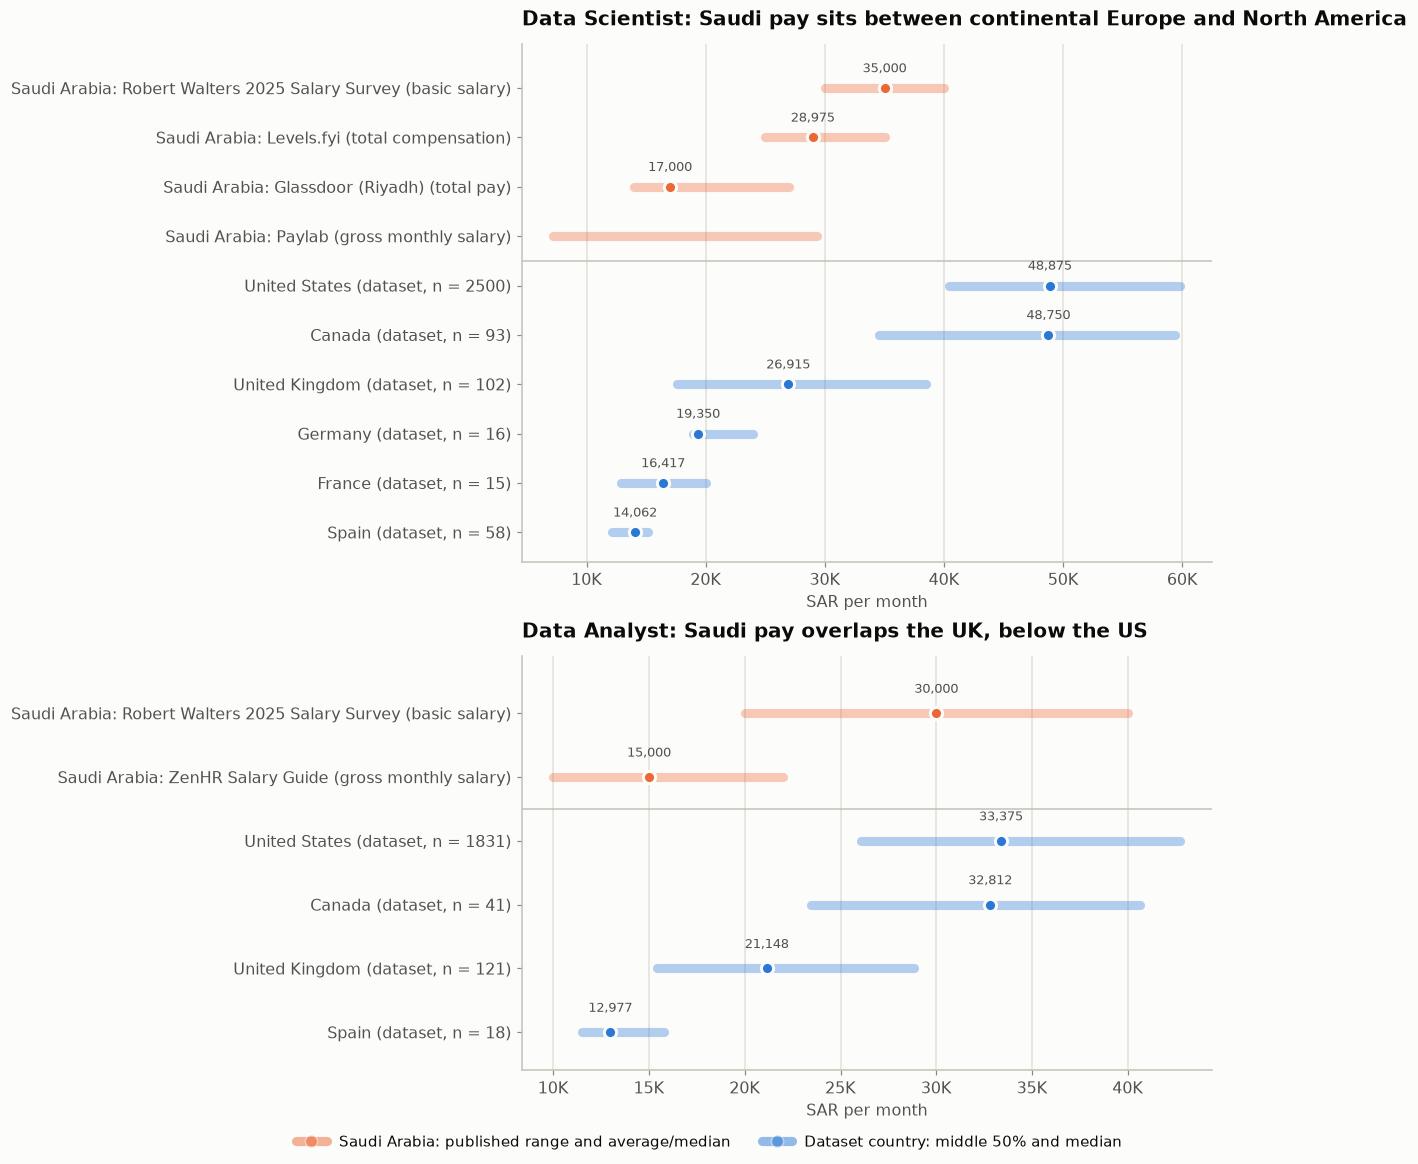

In [45]:
def country_ranges(role, min_n=15):
    sub = df[df.job_title == role]
    g = sub.groupby("company_country").monthly_sar
    out = pd.DataFrame({"low": g.quantile(0.25), "mid": g.median(), "high": g.quantile(0.75), "n": g.size()})
    out = out[out.n >= min_n].sort_values("mid")
    out["label"] = [f"{c} (dataset, n = {n})" for c, n in zip(out.index, out.n)]
    return out


def saudi_ranges(role):
    b = bench[bench.role == role].copy()
    b["label"] = "Saudi Arabia: " + b.source + " (" + b.pay_basis.str.split(" (", regex=False).str[0].str.lower() + ")"
    return b.rename(columns={"min_sar_month": "low", "mid_sar_month": "mid", "max_sar_month": "high"})


from matplotlib.lines import Line2D

fig, axes = plt.subplots(2, 1, figsize=(11, 10.5), height_ratios=[1.25, 1], layout="constrained")
titles = {"Data Scientist": "Data Scientist: Saudi pay sits between continental Europe and North America",
          "Data Analyst": "Data Analyst: Saudi pay overlaps the UK, below the US"}
for ax, role in zip(axes, ["Data Scientist", "Data Analyst"]):
    world, saudi = country_ranges(role), saudi_ranges(role).sort_values("mid", na_position="first")
    rows = list(world[["label", "low", "mid", "high"]].itertuples(index=False))
    rows += list(saudi[["label", "low", "mid", "high"]].itertuples(index=False))
    for y, (label, lo, mid, hi) in enumerate(rows):
        is_sa = label.startswith("Saudi")
        color = S.ORANGE if is_sa else S.BLUE
        if pd.notna(lo) and pd.notna(hi):
            ax.plot([lo, hi], [y, y], color=color, lw=6, alpha=0.35, solid_capstyle="round")
        if pd.notna(mid):
            ax.plot(mid, y, "o", color=color, markersize=8, markeredgecolor=S.SURFACE, markeredgewidth=2)
            ax.text(mid, y + 0.32, f"{mid:,.0f}", ha="center", fontsize=8.5, color=S.INK_SECONDARY)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows])
    ax.set_ylim(-0.6, len(rows) - 0.1)
    ax.axhline(len(world) - 0.5, color=S.AXIS, lw=1)
    ax.xaxis.set_major_formatter(K)
    ax.set_xlabel("SAR per month")
    ax.set_title(titles[role])
    ax.grid(axis="y", visible=False)
handles = [Line2D([0], [0], color=S.ORANGE, lw=6, alpha=0.5, marker="o", markerfacecolor=S.ORANGE,
                  markeredgecolor=S.SURFACE, markersize=8, label="Saudi Arabia: published range and average/median"),
           Line2D([0], [0], color=S.BLUE, lw=6, alpha=0.5, marker="o", markerfacecolor=S.BLUE,
                  markeredgecolor=S.SURFACE, markersize=8, label="Dataset country: middle 50% and median")]
fig.legend(handles=handles, loc="outside lower center", ncol=2)
save(fig, "16_saudi_comparison")

**Insight**

* **Data Scientist:** published Saudi figures run from about 17,000 SAR per month (Glassdoor median, total pay) to 35,000 SAR per month (Robert Walters average, basic salary). That places Saudi Arabia **above the continental European countries in this data** (Germany 19,350, France 16,417, Spain 14,062), **around the UK** (26,915) and **below the US and Canada** (about 48,800).
* **Data Analyst:** Saudi figures (15,000 to 30,000 SAR per month) bracket the UK (21,148), are above Spain (12,977) and below the US (33,375).
* The Saudi sources disagree with each other. Recruiter surveys reflect roles placed through recruiters, often more senior and at larger employers, while crowd-sourced sites have small samples. Robert Walters reports basic salary only, so full Saudi packages with allowances are higher still.

### Senior leadership in Saudi Arabia vs the dataset

In [46]:
lead_titles = ["Head of Data", "Director of Data Science", "Head of Data Science", "Data Science Manager"]
lead_ds = (df[df.job_title.isin(lead_titles)].groupby("job_title").monthly_sar
           .agg(median="median", n="size").round(0))
lead_ds["source"] = "Dataset (mostly US)"
lead_sa = bench[bench.level_note == "Leadership"].set_index("role")[["mid_sar_month"]].rename(
    columns={"mid_sar_month": "median"})
lead_sa["n"] = np.nan
lead_sa["source"] = "Saudi Arabia, Robert Walters (basic salary, average)"
pd.concat([lead_ds, lead_sa]).sort_values("median", ascending=False)

,median,n,source
Head of AI,"100,000.00",NaN,"Saudi Arabia, Robert Walters (basic salary, av..."
Head of Machine Learning,"95,000.00",NaN,"Saudi Arabia, Robert Walters (basic salary, av..."
Chief Data Officer,"85,000.00",NaN,"Saudi Arabia, Robert Walters (basic salary, av..."
Head of Data Analytics,"70,000.00",NaN,"Saudi Arabia, Robert Walters (basic salary, av..."
Director of Data Science,"67,812.00",33.00,Dataset (mostly US)
Head of Data,"67,188.00",45.00,Dataset (mostly US)
Data Science Manager,"59,297.00",108.00,Dataset (mostly US)
Head of Data Science,"51,588.00",12.00,Dataset (mostly US)


**Insight:** for leadership the picture changes. Robert Walters reports Saudi averages of **70,000 to 100,000 SAR per month in basic salary** for Head of Data Analytics, Head of Machine Learning, Head of AI and Chief Data Officer. That is above the dataset medians for similar, mostly US, leadership titles (about 52,000 to 68,000 SAR per month). Senior data and AI leaders appear to be paid very competitively in Saudi Arabia. The titles are not perfectly comparable, so treat this as an indication, not a precise comparison.

## 7. From EDA to machine learning

### 7.1 Features: what goes in and what stays out

| Used as model input | Why |
|---|---|
| `job_title` (grouped: titles with 30+ rows kept, rare titles become "Other + family") | Strongest factor |
| `job_family`, `title_seniority` (built from the title) | Help rare titles borrow information from similar ones |
| `company_location` (grouped: countries with 20+ rows kept, others become "Other + region") and `region` | Location is the second strongest factor |
| `experience_level` (as rank 1 to 4) | Strong, ordered |
| `company_size` (as rank 1 to 3), `work_mode`, `employment_type`, `work_year` | Smaller but real effects |

| Left out | Why |
|---|---|
| `salary`, `salary_currency` | **Leakage**: `salary` is the target in another currency |
| `salary_band`, `salary_sar`, `log_salary`, `is_outlier` | Built from the target, so also leakage |
| `employee_residence` | Same as `company_location` for 99% of rows (redundant) |

**Feature selection from EDA:** the strongest relationships in section 5 were job title (0.44), job family (0.37), experience (0.35) and company country (0.34), so these are the core inputs. Weaker factors (work mode, company size, employment type, year) are kept because they are cheap and the model can learn that they matter little; Chart 19 confirms this.

**Encoding:** text cannot go into a model directly.
* **One-hot encoding** for categories without order (job title group, job family, location, region, work mode, employment type).
* **Label (ordinal) encoding** for ordered categories: experience Entry to Executive becomes 1 to 4, company size Small to Large becomes 1 to 3.

**Scaling:** needed for Linear Regression (also for Logistic Regression and KNN in section 7.10), not for tree-based models.

Rare groups are learned from the training data only, inside the pipeline, so the test data never influences them. The full pipeline is shown below.

### 7.2 Train / test split

Based on section 2.3, the model is trained on **unique rows** (duplicates removed), which avoids identical rows appearing in both train and test. 80% train, 20% test.

In [47]:
model_df = F.model_frame(df, drop_duplicates=True)
train, test = train_test_split(model_df, test_size=0.2, random_state=M.RANDOM_STATE)
X_train, y_train = train[F.MODEL_INPUTS], train[F.TARGET]
X_test, y_test = test[F.MODEL_INPUTS], test[F.TARGET]
print(f"Model rows: {len(model_df):,} | train: {len(train):,} | test: {len(test):,}")
M.make_pipeline(LinearRegression()).named_steps["features"].fit_transform(X_train).head()

Model rows: 8,594 | train: 6,875 | test: 1,719


,title_group,job_family,title_seniority,location_group,region,work_mode,employment_type,experience_rank,company_size_rank,work_year
10983,Research Scientist,Research,Individual contributor,US,North America,On-site,FT,3.00,2.00,"2,023.00"
2353,Research Engineer,Research,Individual contributor,US,North America,On-site,FT,3.00,2.00,"2,024.00"
12655,Data Engineer,Data Engineering,Individual contributor,US,North America,Remote,FT,3.00,2.00,"2,022.00"
2204,Data Scientist,Data Science,Individual contributor,US,North America,On-site,FT,2.00,2.00,"2,024.00"
1309,Other Analytics & BI,Analytics & BI,Leadership,US,North America,Remote,FT,3.00,2.00,"2,024.00"


In [48]:
# The full pipeline: build features, encode and scale, then the model (log of salary as the target)
M.make_pipeline(Ridge(), scale_numeric=True, log_target=True)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.","Pipeline(step...l', Ridge())])"
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'exp'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,min_title_count,30
,min_country_count,20


### 7.3 Baseline: what if we always guessed the median?

Any useful model must beat this.

In [49]:
baseline = M.regression_metrics(y_test, np.full(len(y_test), y_train.median()))
baseline

{'MAE': 54240.344386271085,
 'MSE': 5090908020.437464,
 'RMSE': 71350.59929977788,
 'R2': -0.019383944091860617}

### 7.4 Model comparison with 5-fold cross-validation

Four models from the course, each trained on the raw salary and on the log of salary (the log reduces the effect of the very high salaries).
Cross-validation trains and scores each model 5 times on different slices of the training data, which gives a more stable comparison than a single split.

In [50]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=M.RANDOM_STATE)
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
cv_rows = []
for name, (est, scale) in M.candidate_models().items():
    for log_target in [False, True]:
        r = cross_validate(M.make_pipeline(est, scale, log_target), X_train, y_train, cv=cv, scoring=scoring)
        cv_rows.append({"model": name, "target": "log(salary)" if log_target else "salary",
                        "CV MAE": -r["test_MAE"].mean(), "CV MAE sd": r["test_MAE"].std(),
                        "CV RMSE": -r["test_RMSE"].mean(), "CV R2": r["test_R2"].mean(),
                        "fit seconds": r["fit_time"].mean()})
cv_table = pd.DataFrame(cv_rows).sort_values("CV MAE").reset_index(drop=True)
cv_table.round(3)

,model,target,CV MAE,CV MAE sd,CV RMSE,CV R2,fit seconds
0,Linear Regression,log(salary),"41,896.48",975.18,"61,704.82",0.30,0.08
1,Gradient Boosting,log(salary),"42,151.87",551.12,"61,875.16",0.29,1.20
2,Random Forest,log(salary),"42,386.65",613.68,"62,177.00",0.28,1.27
3,Decision Tree,log(salary),"42,567.17",545.23,"62,450.29",0.28,0.06
4,Linear Regression,salary,"42,958.22",692.45,"61,187.23",0.31,0.07
5,Gradient Boosting,salary,"43,089.00",317.89,"61,469.71",0.30,1.16
6,Decision Tree,salary,"43,278.29",202.84,"61,885.00",0.29,0.07
7,Random Forest,salary,"43,306.18",361.48,"61,774.24",0.29,1.19


### Chart 17: Model comparison

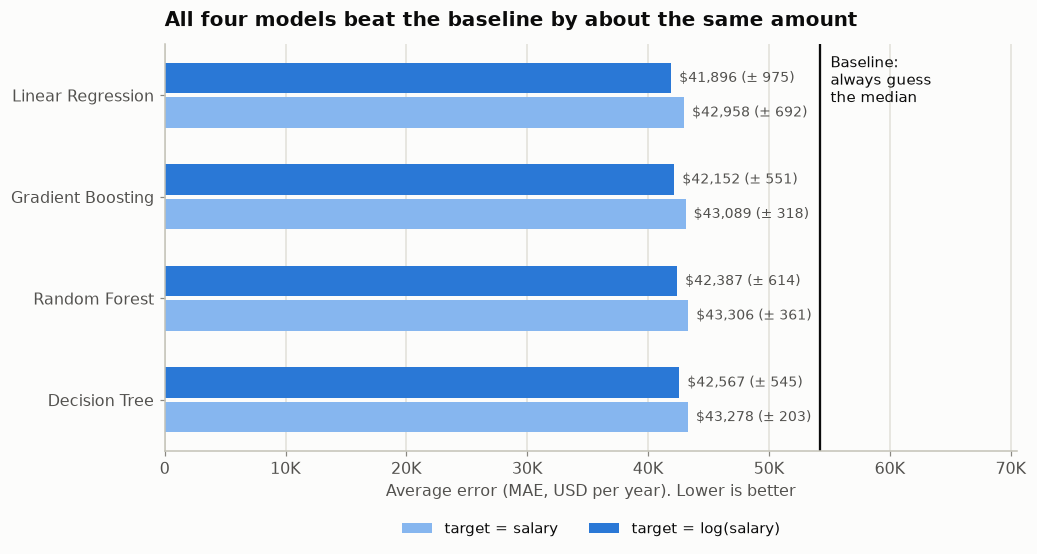

In [51]:
order = cv_table.groupby("model")["CV MAE"].min().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 4.8))
yy = np.arange(len(order))
for offset, (target, color) in zip([-0.17, 0.17], [("salary", "#86b6ef"), ("log(salary)", S.BLUE)]):
    vals = cv_table[cv_table.target == target].set_index("model").loc[order]
    ax.barh(yy + offset, vals["CV MAE"], height=0.3, color=color, label=f"target = {target}")
    for y, (v, sd) in zip(yy + offset, vals[["CV MAE", "CV MAE sd"]].values):
        ax.text(v, y, f"  {usd(v)} (± {sd:,.0f})", va="center", fontsize=9, color=S.INK_SECONDARY)
ax.axvline(baseline["MAE"], color=S.INK, lw=1.5)
ax.text(baseline["MAE"], len(order) - 0.6, "  Baseline:\n  always guess\n  the median", fontsize=9.5, va="top")
ax.set_yticks(yy, order)
ax.set_xlim(0, baseline["MAE"] * 1.3)
ax.xaxis.set_major_formatter(K)
ax.set_xlabel("Average error (MAE, USD per year). Lower is better")
ax.set_title("All four models beat the baseline by about the same amount")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
ax.grid(axis="y", visible=False)
save(fig, "17_model_comparison")

**Insight:** every model cuts the error by about the same amount compared with the baseline (from $54,240 to about $42,000). The differences between models (a few hundred dollars) are smaller than the normal variation between folds (±$200 to ±$975). Training on the log of salary lowers the error for every model, because it stops the few very high salaries from dominating. **The limit is the information in the data, not the choice of algorithm.**

### 7.5 Choosing the model

**Rule:** take the model with the lowest cross-validated MAE. If other models are within one standard deviation of it (the normal fold-to-fold noise), the difference is not real, so prefer the simplest of them, because it is easier to explain and more predictable.

In [52]:
simplicity = {"Linear Regression": 0, "Decision Tree": 1, "Random Forest": 2, "Gradient Boosting": 3}
best = cv_table.iloc[0]
contenders = cv_table[cv_table["CV MAE"] <= best["CV MAE"] + best["CV MAE sd"]].copy()
contenders["simplicity"] = contenders.model.map(simplicity)
chosen = contenders.sort_values(["simplicity", "CV MAE"]).iloc[0]
print(f"Lowest CV MAE: {best.model} ({best.target}) {usd(best['CV MAE'])} ± {best['CV MAE sd']:,.0f}")
print(f"Within noise: {', '.join(contenders.model + ' (' + contenders.target + ')')}")
print(f"Chosen: {chosen.model} with target {chosen.target}")

Lowest CV MAE: Linear Regression (log(salary)) $41,896 ± 975
Within noise: Linear Regression (log(salary)), Gradient Boosting (log(salary)), Random Forest (log(salary)), Decision Tree (log(salary))
Chosen: Linear Regression with target log(salary)


### 7.6 Light tuning

For Linear Regression we add a small penalty (Ridge regression) that keeps the model stable when categories overlap (for example a title group and its job family). We test a few penalty strengths.

In [53]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

log_chosen = chosen.target == "log(salary)"
grids = {
    "Linear Regression": (Ridge(), True, {"model__alpha": [0.1, 1, 3, 10, 30]}),
    "Decision Tree": (DecisionTreeRegressor(random_state=42), False,
                      {"model__max_depth": [6, 8, 12], "model__min_samples_leaf": [10, 20, 40]}),
    "Random Forest": (RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=42), False,
                      {"model__min_samples_leaf": [3, 5, 10], "model__max_features": [0.5, 1.0]}),
    "Gradient Boosting": (HistGradientBoostingRegressor(random_state=42), False,
                          {"model__learning_rate": [0.05, 0.1], "model__max_leaf_nodes": [10, 31],
                           "model__min_samples_leaf": [20, 40]}),
}
est, scale, grid = grids[chosen.model]
pipe = M.make_pipeline(est, scale, log_chosen)
if log_chosen:
    grid = {f"regressor__{k}": v for k, v in grid.items()}
search = GridSearchCV(pipe, grid, cv=cv, scoring="neg_mean_absolute_error").fit(X_train, y_train)
tuning = (pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]]
          .assign(**{"CV MAE": lambda d: -d.mean_test_score}).sort_values("CV MAE"))
print("Best settings:", search.best_params_)
tuning[["params", "CV MAE", "std_test_score"]].round(1)

Best settings: {'regressor__model__alpha': 10}


,params,CV MAE,std_test_score
3,{'regressor__model__alpha': 10},"41,862.80",964.60
2,{'regressor__model__alpha': 3},"41,877.40",971.00
1,{'regressor__model__alpha': 1},"41,888.10",972.00
0,{'regressor__model__alpha': 0.1},"41,895.60",974.80
4,{'regressor__model__alpha': 30},"41,915.80",947.10


### 7.7 Final model on the test set (data it has never seen)

In [54]:
best_params = {k.split("__")[-1]: v for k, v in search.best_params_.items()}
from sklearn.base import clone
final_estimator = clone(est).set_params(**best_params)
final_name = "Linear Regression (Ridge)" if chosen.model == "Linear Regression" else chosen.model
bundle = M.train_bundle(train, final_name, final_estimator, scale, log_chosen)
pred = M.predict_salary(bundle, test)
test_metrics = M.regression_metrics(y_test, pred.predicted)
ape = (pred.predicted - y_test).abs() / y_test
coverage = ((y_test >= pred.low) & (y_test <= pred.high)).mean()
summary = pd.DataFrame({
    "Final model": [test_metrics[k] for k in ["MAE", "MSE", "RMSE", "R2"]],
    "Baseline (median)": [baseline[k] for k in ["MAE", "MSE", "RMSE", "R2"]],
}, index=["MAE", "MSE", "RMSE", "R2"])
print(f"Average error: {usd(test_metrics['MAE'])} per year ({sar_month(test_metrics['MAE'])}), "
      f"{1 - test_metrics['MAE'] / baseline['MAE']:.0%} better than the baseline")
print(f"Predictions within 20% of the real salary: {(ape <= 0.2).mean():.0%} | within 30%: {(ape <= 0.3).mean():.0%}")
print(f"The predicted range (10th to 90th percentile) contained the real salary for {coverage:.0%} of test rows")
summary.round(3)

Average error: $41,939 per year (13,106 SAR/month), 23% better than the baseline
Predictions within 20% of the real salary: 42% | within 30%: 60%
The predicted range (10th to 90th percentile) contained the real salary for 76% of test rows


,Final model,Baseline (median)
MAE,"41,938.50","54,240.34"
MSE,"3,490,631,732.35","5,090,908,020.44"
RMSE,"59,081.57","71,350.60"
R2,0.30,-0.02


**Why can't the model be more precise?** Look at people who have *exactly the same inputs*:

In [55]:
profile_spread = (model_df.groupby(F.MODEL_INPUTS).salary_in_usd
                  .agg(people="size", lowest="min", p25=lambda s: s.quantile(0.25), median="median",
                       p75=lambda s: s.quantile(0.75), highest="max")
                  .sort_values("people", ascending=False).head(5))
top_profile = profile_spread.iloc[0]
print("Most common profile:", ", ".join(f"{k} = {v}" for k, v in zip(F.MODEL_INPUTS, profile_spread.index[0])))
print(f"{int(top_profile.people)} unique records, salaries from {usd(top_profile.lowest)} to {usd(top_profile.highest)}, "
      f"middle half {usd(top_profile.p25)} to {usd(top_profile.p75)}")
profile_spread.round(0)

Most common profile: job_title = Data Scientist, experience_level = SE, company_location = US, company_size = M, remote_ratio = 0, employment_type = FT, work_year = 2023
300 unique records, salaries from $70,000 to $750,000, middle half $138,850 to $216,275


,,,,,,,people,lowest,p25,median,p75,highest
job_title,experience_level,company_location,company_size,remote_ratio,employment_type,work_year,,,,,,
Data Scientist,SE,US,M,0,FT,2023,300,70000,"138,850.00","173,100.00","216,275.00",750000
Data Engineer,SE,US,M,0,FT,2023,285,50000,"120,000.00","158,700.00","205,000.00",385000
Machine Learning Engineer,SE,US,M,0,FT,2023,209,66000,"147,000.00","188,800.00","241,300.00",392000
Data Scientist,SE,US,M,100,FT,2023,193,80000,"140,250.00","173,000.00","207,345.00",297300
Data Engineer,SE,US,M,100,FT,2023,186,63000,"121,875.00","153,800.00","196,675.00",305000


**Insight in plain words**

* The model's typical error is about **$41,900 per year** (about 13,100 SAR per month), **23% better** than always guessing the median.
* It explains about **30%** of the differences in salary (R² = 0.30).
* **42%** of predictions land within 20% of the real salary, and **60%** within 30%.
* The predicted range contained the real salary for **76%** of people (it was designed for 80%).

**Why not higher?** The table above answers it. The most common profile in the data (Senior Data Scientist, US, medium company, on-site, full-time, 2023) has 300 unique records with salaries from **$70,000 to $750,000**, and the middle half alone spans $138,850 to $216,275. These people look identical to the model, so no algorithm can tell them apart. What would explain the difference (the specific company, city, years of experience, skills, education, bonuses and equity) is not in the data.

### Chart 18: Predicted vs actual salary

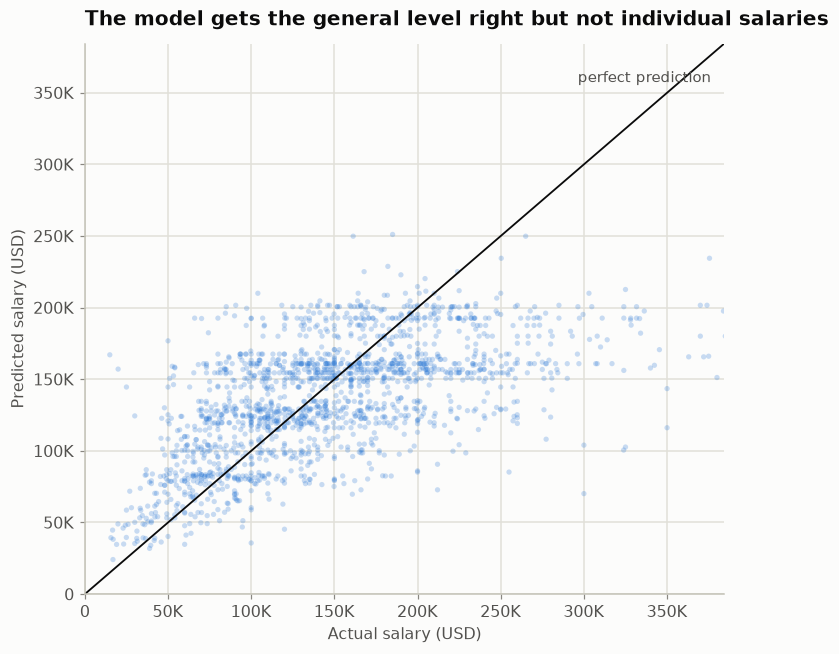

In [56]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.scatter(y_test, pred.predicted, s=12, color=S.BLUE, alpha=0.25, edgecolor="none")
lim = [0, np.percentile(y_test, 99.5)]
ax.plot(lim, lim, color=S.INK, lw=1.2)
ax.text(lim[1] * 0.98, lim[1] * 0.93, "perfect prediction", ha="right", fontsize=9.5, color=S.INK_SECONDARY)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.xaxis.set_major_formatter(K)
ax.yaxis.set_major_formatter(K)
ax.set_xlabel("Actual salary (USD)")
ax.set_ylabel("Predicted salary (USD)")
ax.set_title("The model gets the general level right but not individual salaries")
save(fig, "18_predicted_vs_actual")

**Insight:** points gather around the diagonal for typical salaries, but the model is cautious at the extremes: it rarely predicts above $250,000 and over-predicts some low salaries. That is the expected behaviour when the inputs cannot separate people with the same title, level and country but very different pay.

### Chart 19: What does the model rely on? (permutation importance)

We shuffle one input at a time and measure how much worse the predictions get. A bigger increase in error means the model relies more on that input.

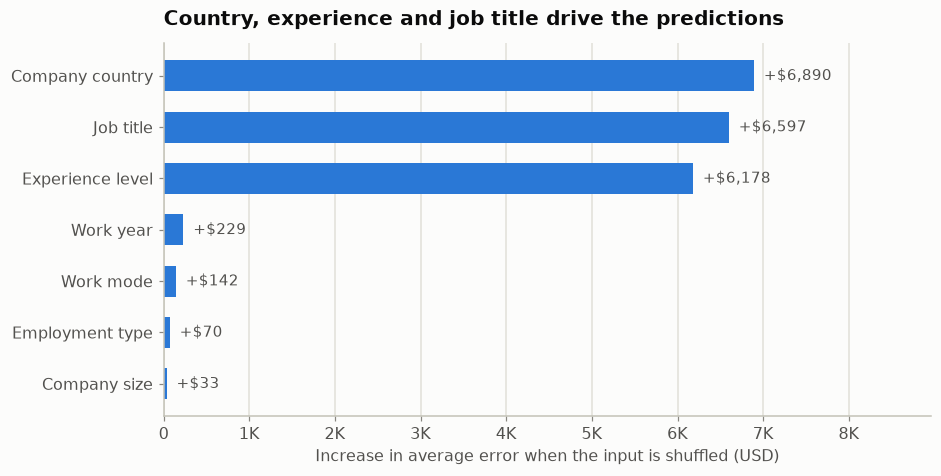

In [57]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(bundle["model"], X_test, y_test, n_repeats=10, random_state=42,
                              scoring="neg_mean_absolute_error")
input_names = {"job_title": "Job title", "experience_level": "Experience level", "company_location": "Company country",
               "company_size": "Company size", "remote_ratio": "Work mode", "employment_type": "Employment type",
               "work_year": "Work year"}
importance = pd.DataFrame({"input": [input_names[c] for c in F.MODEL_INPUTS],
                           "MAE increase": perm.importances_mean, "sd": perm.importances_std}).sort_values("MAE increase")
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(importance.input, importance["MAE increase"], color=S.BLUE, height=0.6)
for y, v in enumerate(importance["MAE increase"]):
    ax.text(v, y, f"  +{usd(v)}", va="center", fontsize=9.5, color=S.INK_SECONDARY)
ax.set_xlim(0, importance["MAE increase"].max() * 1.3)
ax.xaxis.set_major_formatter(K)
ax.set_xlabel("Increase in average error when the input is shuffled (USD)")
ax.set_title("Country, experience and job title drive the predictions")
ax.grid(axis="y", visible=False)
save(fig, "19_feature_importance")

**Insight:** shuffling company country, job title or experience level each raises the error by about $6,000 to $7,000, while the other inputs matter very little. Company size looked important in Chart 10, but once country is known it adds almost nothing, because small companies in this data are mostly outside the US. The model learned the real driver (location) rather than the proxy (size).

### Chart 20: What the model learned, in one picture

Predicted salary for a Data Scientist at a medium-size company, on-site, full-time, in 2024.

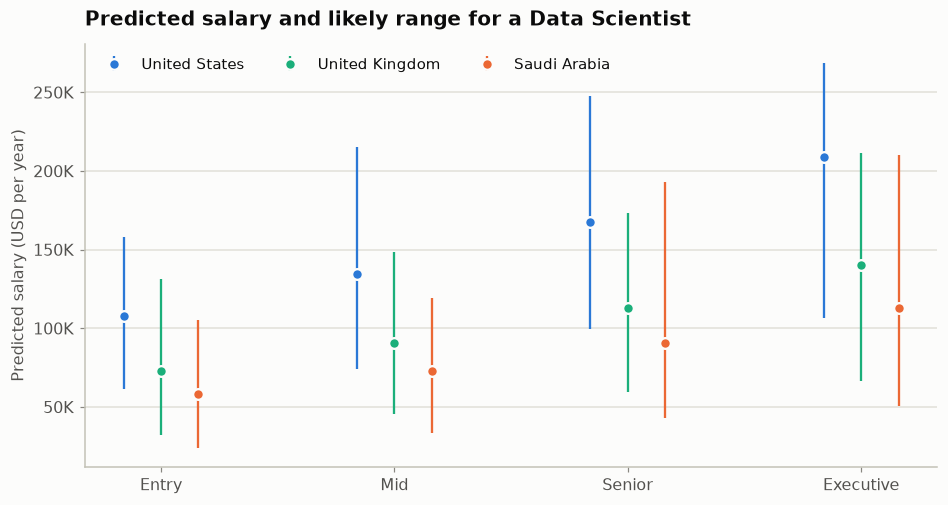

country,Saudi Arabia,United Kingdom,United States
experience,,,
Entry,"58,500.00","72,600.00","108,100.00"
Mid,"72,800.00","90,500.00","134,600.00"
Senior,"90,700.00","112,600.00","167,600.00"
Executive,"112,900.00","140,200.00","208,600.00"


In [58]:
profiles = pd.DataFrame([{"job_title": "Data Scientist", "experience_level": e, "company_location": c,
                          "company_size": "M", "remote_ratio": 0, "employment_type": "FT", "work_year": 2024}
                         for c in ["US", "GB", "SA"] for e in ["EN", "MI", "SE", "EX"]])
prof_pred = M.predict_salary(bundle, profiles).join(profiles)
prof_pred["country"] = prof_pred.company_location.map(F.COUNTRY_NAMES)
prof_pred["experience"] = prof_pred.experience_level.map(F.EXPERIENCE_LABELS)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(4)
country_colors = {"United States": S.BLUE, "United Kingdom": S.CATEGORICAL[2], "Saudi Arabia": S.ORANGE}
for i, (country, color) in enumerate(country_colors.items()):
    sub = prof_pred[prof_pred.country == country]
    ax.errorbar(x + (i - 1) * 0.16, sub.predicted, yerr=[sub.predicted - sub.low, sub.high - sub.predicted],
                fmt="o", color=color, markersize=7, markeredgecolor=S.SURFACE, markeredgewidth=1.5,
                elinewidth=1.5, capsize=0, label=country)
ax.set_xticks(x, F.EXPERIENCE_ORDER)
ax.yaxis.set_major_formatter(K)
ax.set_ylabel("Predicted salary (USD per year)")
ax.set_title("Predicted salary and likely range for a Data Scientist")
ax.legend(ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
save(fig, "20_prediction_profiles")
prof_pred.pivot_table(index="experience", columns="country", values="predicted").reindex(F.EXPERIENCE_ORDER).round(-2)

**Insight:** the pattern is easy to read: salary climbs with experience in every country, and the US sits well above the others. The vertical bars show the likely range (10th to 90th percentile), which is wide because people with the same profile earn very different amounts.

The Saudi estimate is built from very few Middle East records, so it should be checked against section 6. The model's Senior Data Scientist estimate for Saudi Arabia (about **$90,700 per year, about 28,300 SAR per month**) falls inside the range of the published Saudi figures (17,000 to 35,000 SAR per month), which is reassuring but not proof.

### 7.8 Sanity checks

Automatic checks that the model behaves sensibly. The notebook stops with an error if any check fails.

In [59]:
us_ds = prof_pred[prof_pred.company_location == "US"].set_index("experience_level").predicted
checks = {
    "Entry < Mid < Senior < Executive (US Data Scientist)": bool(us_ds["EN"] < us_ds["MI"] < us_ds["SE"] < us_ds["EX"]),
    "US prediction > UK prediction (Senior)": bool(us_ds["SE"] > prof_pred.query("company_location == 'GB' and experience_level == 'SE'").predicted.iloc[0]),
    "All predictions positive": bool((pred.predicted > 0).all()),
    "low <= predicted <= high everywhere": bool(((pred.low <= pred.predicted) & (pred.predicted <= pred.high)).all()),
    "Beats the baseline by at least 15%": bool(test_metrics["MAE"] < 0.85 * baseline["MAE"]),
    "Unknown title and country still give a prediction": bool(np.isfinite(M.predict_salary(bundle, pd.DataFrame([{
        "job_title": "Brand New Title", "experience_level": "SE", "company_location": "ZZ", "company_size": "M",
        "remote_ratio": 0, "employment_type": "FT", "work_year": 2024}])).predicted.iloc[0])),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", name)
assert all(checks.values())

PASS Entry < Mid < Senior < Executive (US Data Scientist)
PASS US prediction > UK prediction (Senior)
PASS All predictions positive
PASS low <= predicted <= high everywhere
PASS Beats the baseline by at least 15%
PASS Unknown title and country still give a prediction


### 7.9 Save the model for the Streamlit app

The evaluation above used the 80% training split. For the app, the same model and settings are refitted on **all** unique rows, so it learns from every record. The test-set results are saved alongside it, so the app can show how accurate the model is. Because the refitted model also learns from the test rows, its estimates can shift a little, most of all for countries with very few records such as Saudi Arabia; the cell below prints the deployed model's Saudi estimate for comparison with Chart 20.

In [60]:
final_bundle = M.train_bundle(model_df, final_name, final_estimator, scale, log_chosen,
                              test_metrics={**test_metrics, "baseline_MAE": baseline["MAE"],
                                            "within_20pct": float((ape <= 0.2).mean()),
                                            "within_30pct": float((ape <= 0.3).mean()),
                                            "range_coverage": float(coverage),
                                            "test_rows": int(len(test))},
                              extra={"best_params": {k: (float(v) if isinstance(v, (int, float)) else v)
                                                     for k, v in best_params.items()},
                                     "duplicates_dropped_for_model": True})
M.save_bundle(final_bundle)

eval_dir = ROOT / "models"
pd.DataFrame({"actual": y_test.values, "predicted": pred.predicted.values, "low": pred.low.values,
              "high": pred.high.values}).to_csv(eval_dir / "test_predictions.csv", index=False)
cv_table.to_csv(eval_dir / "model_comparison.csv", index=False)
importance.to_csv(eval_dir / "feature_importance.csv", index=False)
dup_results.reset_index().to_csv(eval_dir / "duplicates_experiment.csv", index=False)

reloaded = M.load_bundle()
check = M.predict_salary(reloaded, test.head(5))
assert np.allclose(check.predicted, M.predict_salary(final_bundle, test.head(5)).predicted)
print("Saved and reloaded:", M.BUNDLE_PATH.relative_to(ROOT), f"({M.BUNDLE_PATH.stat().st_size / 1e6:.2f} MB)")
sa_deployed = M.predict_salary(final_bundle, profiles.query("company_location == 'SA' and experience_level == 'SE'")).predicted.iloc[0]
print(f"Deployed model, Senior Data Scientist in Saudi Arabia: {usd(sa_deployed)} per year ({sar_month(sa_deployed)})")
print(final_bundle["meta"])

Saved and reloaded: models/salary_model.joblib (0.72 MB)
Deployed model, Senior Data Scientist in Saudi Arabia: $104,459 per year (32,644 SAR/month)
{'model_name': 'Linear Regression (Ridge)', 'log_target': True, 'trained_on_rows': 8594, 'trained_on': '2026-10-23', 'sklearn_version': '1.9.1', 'inputs': ['job_title', 'experience_level', 'company_location', 'company_size', 'remote_ratio', 'employment_type', 'work_year'], 'range_quantiles': [0.1, 0.9], 'test_metrics': {'MAE': 41938.5052944122, 'MSE': 3490631732.3516684, 'RMSE': 59081.56846556858, 'R2': 0.30104925714389896, 'baseline_MAE': 54240.344386271085, 'within_20pct': 0.41942990110529377, 'within_30pct': 0.6015125072716696, 'range_coverage': 0.7550901687027342, 'test_rows': 1719}, 'best_params': {'alpha': 10.0}, 'duplicates_dropped_for_model': True}


### 7.10 The same question as a classification problem

Unit 3 (Part 5) shows that one dataset can be framed two ways. Instead of predicting the exact salary (regression), we can predict a **salary level**: Low, Medium or High (each third of the training salaries).
This uses the classification models and metrics from the course: Accuracy, Precision, Recall and F1.

In [61]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from src.features import SalaryFeatureBuilder

# Thresholds come from the TRAINING data only, to avoid leakage
t1, t2 = y_train.quantile([1 / 3, 2 / 3])
levels = ["Low", "Medium", "High"]
to_level = lambda y: pd.cut(y, [-np.inf, t1, t2, np.inf], labels=levels).astype(str)
yc_train, yc_test = to_level(y_train), to_level(y_test)
print(f"Low: below {usd(t1)} | Medium: {usd(t1)} to {usd(t2)} | High: above {usd(t2)}")

classifiers = {
    "Logistic Regression": (LogisticRegression(max_iter=2000), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=42), False),
    "Random Forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42), False),
    "KNN": (KNeighborsClassifier(n_neighbors=25), True),
}
clf_rows, fitted = [], {}
for name, (clf, scale) in classifiers.items():
    pipe = Pipeline([("features", SalaryFeatureBuilder()), ("prep", M.make_preprocessor(scale)), ("model", clf)])
    pipe.fit(X_train, yc_train)
    p = pipe.predict(X_test)
    fitted[name] = p
    clf_rows.append({"model": name, "Accuracy": accuracy_score(yc_test, p),
                     "Precision": precision_score(yc_test, p, average="macro"),
                     "Recall": recall_score(yc_test, p, average="macro"),
                     "F1": f1_score(yc_test, p, average="macro")})
clf_table = pd.DataFrame(clf_rows).sort_values("F1", ascending=False).reset_index(drop=True)
clf_table.to_csv(ROOT / "models" / "classification_comparison.csv", index=False)
print("Random guessing would score about 0.33 on every metric (three equal classes).")
clf_table.round(3)

Low: below $110,000 | Medium: $110,000 to $167,500 | High: above $167,500


Random guessing would score about 0.33 on every metric (three equal classes).


,model,Accuracy,Precision,Recall,F1
0,KNN,0.56,0.55,0.55,0.55
1,Logistic Regression,0.56,0.55,0.55,0.54
2,Decision Tree,0.55,0.55,0.54,0.53
3,Random Forest,0.55,0.53,0.54,0.52


### Chart 21: Confusion matrix of the best classifier

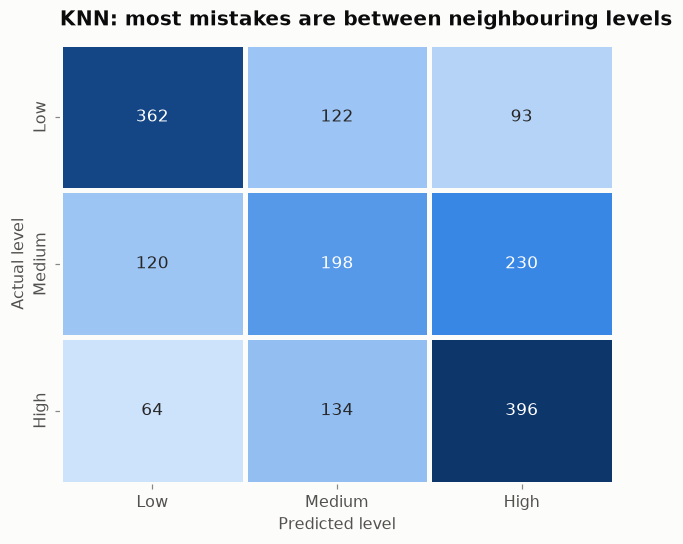

              precision    recall  f1-score   support

         Low      0.663     0.627     0.645       577
      Medium      0.436     0.361     0.395       548
        High      0.551     0.667     0.603       594

    accuracy                          0.556      1719
   macro avg      0.550     0.552     0.548      1719
weighted avg      0.552     0.556     0.551      1719



In [62]:
best_clf = clf_table.model.iloc[0]
cm = confusion_matrix(yc_test, fitted[best_clf], labels=levels)
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(cm, annot=True, fmt="d", cmap=sns.blend_palette(S.SEQUENTIAL, as_cmap=True), cbar=False,
            xticklabels=levels, yticklabels=levels, linewidths=2, linecolor=S.SURFACE, ax=ax, annot_kws={"fontsize": 11})
ax.set_xlabel("Predicted level")
ax.set_ylabel("Actual level")
ax.set_title(f"{best_clf}: most mistakes are between neighbouring levels")
ax.grid(False)
save(fig, "21_confusion_matrix")
print(classification_report(yc_test, fitted[best_clf], labels=levels, digits=3))

**What we see and why it matters**

* All four classifiers reach about **55% to 56% accuracy** (macro F1 about 0.52 to 0.55), well above the 33% of random guessing but far from perfect. It is the same message as the regression: the data supports rough salary levels, not precise salaries.
* The best model here (KNN, accuracy 0.56) recognises **Low** (F1 0.65) and **High** (F1 0.60) best and struggles with **Medium** (F1 0.40), which is confused with both neighbours.
* Most mistakes are between neighbouring levels (606 cases) rather than Low vs High (157 cases).

The regression model remains the main model because it gives a salary figure and a range, which is more useful than a level.

### 7.11 Fact check

Every number quoted in the text of this notebook is checked here against the data, so the text cannot drift from the results.

In [63]:
facts = {
    "rows": (len(df), 13972),
    "duplicates": (dup_before, 5378),
    "median salary": (df.salary_in_usd.median(), 141600),
    "mean salary (rounded)": (round(df.salary_in_usd.mean()), 150029),
    "Q1 / Q3": ((q1, q3), (103000, 185900)),
    "US median / non-US median": ((us_med, non_us_med), (148775, 79833)),
    "experience medians": (tuple(exp["median"]), (82000, 113250, 155000, 190000)),
    "outliers": (len(outliers), 253),
    "naive split leak (%)": (round(leak_share * 100, 1), 50.2),
    "test MAE (nearest 100)": (round(test_metrics["MAE"], -2), 41900),
    "test R2 (2 dp)": (round(test_metrics["R2"], 2), 0.30),
    "better than baseline (%)": (round((1 - test_metrics["MAE"] / baseline["MAE"]) * 100), 23),
    "within 20% / 30%": ((round((ape <= 0.2).mean(), 2), round((ape <= 0.3).mean(), 2)), (0.42, 0.60)),
    "range coverage": (round(coverage, 2), 0.76),
    "duplicates change model MAE by less than $100": (
        bool((dup_results["MAE"].groupby(level="model").agg(lambda s: s.max() - s.min()) < 100).all()), True),
    "hybrid / small-company medians": ((wm.loc["Hybrid", "median"], cs.loc["Small", "median"]), (65666, 73000)),
    "most common profile: records, min, max": (
        (int(top_profile.people), top_profile.lowest, top_profile.highest), (300, 70000, 750000)),
    "IQR steps": ((Q1, Q3, IQR), (103000, 185900, 82900)),
    "correlation with salary: experience, US": (
        (round(corr.loc["Experience rank", "Salary (USD)"], 2), round(corr.loc["US company", "Salary (USD)"], 2)), (0.39, 0.33)),
    "max feature-feature |correlation|": (
        round(corr.drop(index="Salary (USD)", columns="Salary (USD)").where(~np.eye(len(corr) - 1, dtype=bool)).abs().max().max(), 2), 0.20),
    "hybrid share: US / non-US (%)": ((round(shares.loc["Hybrid", "US company"], 1), round(shares.loc["Hybrid", "Non-US company"], 1)), (0.4, 11.0)),
    "best classifier accuracy": (round(accuracy_score(yc_test, fitted[best_clf]), 2), 0.56),
    "neighbouring vs far mistakes": ((int(cm[0, 1] + cm[1, 0] + cm[1, 2] + cm[2, 1]), int(cm[0, 2] + cm[2, 0])), (606, 157)),
    "step-by-step features match src": (True, True),
    "Saudi Senior Data Scientist estimate (nearest 100)": (
        round(prof_pred.query("company_location == 'SA' and experience_level == 'SE'").predicted.iloc[0], -2), 90700),
}
bad = {k: v for k, v in facts.items() if not np.allclose(np.ravel(v[0]), np.ravel(v[1]))}
for k, (got, expected) in facts.items():
    print("PASS" if k not in bad else "FAIL", k, got)
assert not bad, bad

PASS rows 13972
PASS duplicates 5378
PASS median salary 141600.0
PASS mean salary (rounded) 150029
PASS Q1 / Q3 (103000.0, 185900.0)
PASS US median / non-US median (np.float64(148775.0), np.float64(79833.0))
PASS experience medians (82000.0, 113250.0, 155000.0, 190000.0)
PASS outliers 253
PASS naive split leak (%) 50.2
PASS test MAE (nearest 100) 41900.0
PASS test R2 (2 dp) 0.3
PASS better than baseline (%) 23
PASS within 20% / 30% (np.float64(0.42), np.float64(0.6))
PASS range coverage 0.76
PASS duplicates change model MAE by less than $100 True
PASS hybrid / small-company medians (np.float64(65666.0), np.float64(73000.0))
PASS most common profile: records, min, max (300, np.float64(70000.0), np.float64(750000.0))
PASS IQR steps (np.float64(103000.0), np.float64(185900.0), np.float64(82900.0))
PASS correlation with salary: experience, US (np.float64(0.39), np.float64(0.33))
PASS max feature-feature |correlation| 0.2
PASS hybrid share: US / non-US (%) (np.float64(0.4), np.float64(11.0)

## 8. Key findings and limitations

### What the data tells us

1. **Location is the biggest single driver.** US companies pay about 1.9 times the rest of the world (median $148,775 vs $79,833).
2. **Experience pays at every step:** +38% (Entry to Mid), +37% (Mid to Senior), +23% (Senior to Executive).
3. **The type of work matters:** Machine Learning & AI and Research roles earn about 70% more than Analytics & BI.
4. **Remote work does not lower pay.** Remote and on-site medians are almost equal; the low hybrid and small-company figures are mostly a location effect.
5. **Salaries rose sharply in 2022**, and Entry and Mid salaries kept rising into 2024.
6. **Saudi Arabia (external benchmarks):** Data Scientist pay sits above continental Europe and around the UK, below the US; leadership roles are paid very competitively.

### What the model can and cannot do

* **Chosen model:** Linear Regression with a small Ridge penalty, trained on the log of salary. It matched Random Forest and Gradient Boosting and is simpler, faster and easier to explain.
* **Accuracy:** typical error about $41,900 per year, 23% better than guessing, R² = 0.30.
* **As classification** (Low / Medium / High), the best model is right 56% of the time, compared with 33% by chance.
* **Good for:** a realistic salary range for a profile, and understanding which factors matter.
* **Not good for:** an exact offer for one person, or countries with very few records (including Saudi Arabia).

### Limitations

* 87.5% of records are from US companies and only 2 from Saudi Arabia.
* The data covers 2020 to 2024, so it does not reflect 2025 and 2026 pay.
* No information on company, city, skills, education, exact years of experience, bonuses or equity.
* 38.5% of rows are exact duplicates whose origin cannot be verified.
* External Saudi figures use different definitions (basic vs total pay) and are kept separate from the model.

### Saudi benchmark sources

* [Robert Walters Middle East 2025 Salary Survey](https://www.robertwalters.ae/content/dam/robert-walters-redesign/country/middle-east/files/reports---e-guides-2025/Robert%20Walters%20Middle%20East%20-%202025%20Salary%20Survey.pdf) (KSA Technology & Digital tables)
* [Levels.fyi: Data Scientist, Saudi Arabia](https://www.levels.fyi/t/data-scientist/locations/saudi-arabia)
* [Glassdoor: Data Scientist, Riyadh](https://www.glassdoor.com/Salaries/riyadh-saudi-arabia-data-scientist-salary-SRCH_IL.0,19_IM1652_KO20,34.htm)
* [Paylab: Data Scientist, Saudi Arabia](https://saudiarabia.paylab.com/en/salaryinfo/information-technology/data-scientist)
* [ZenHR Saudi Arabia Salary Guide](https://www.zenhr.com/en/salary-guide-ksa)
* [PayScale: Data Engineer, Saudi Arabia](https://www.payscale.com/research/SA/Job=Data_Engineer/Salary/a5bdfd56/Experienced)

### Unit 3 checklist: where each topic is covered

| Unit 3 topic | Section |
|---|---|
| Part 1: what EDA is, data to insight, workflow, analytics types | Introduction |
| Part 1: load and inspect (`head`, `shape`, `columns`, `info`, `describe`) | 1.1 |
| Part 1: target variable, problem type, feature types | 1.3, 1.4, 3 |
| Part 2: univariate numerical (mean, median, std, skewness, histogram, boxplot) | 4.1, Chart 1 |
| Part 2: univariate categorical (categories, most frequent, imbalance, countplot) | 4.2, Charts 2 and 3 |
| Part 2: writing insights (what we see and why it matters) | Insight notes after every chart |
| Part 3: missing values, duplicates, invalid values, data types | 2.1 to 2.4 |
| Part 3: outliers with boxplot and IQR | 2.5, Chart 1 |
| Part 3: cleaning strategy and documented decisions | 2.8 |
| Part 4: categorical vs numerical (groupby, boxplot by category) | 5.1, 5.2, Charts 4 to 12 |
| Part 4: numerical vs numerical (correlation matrix, scatter) | 5.3, Charts 13 and 14 |
| Part 4: categorical vs categorical (crosstab, countplot with hue) | 5.4, Chart 15 |
| Part 4: correlation is not causation, sample size | 5.5 |
| Part 5: define the problem, target, feature selection, leakage | 7.1 |
| Part 5: encoding (one-hot, label) and scaling | 7.1, 7.2 |
| Part 5: models (Linear Regression, Decision Tree, Random Forest, plus Gradient Boosting) | 7.4 to 7.6 |
| Part 5: 80/20 train/test split | 7.2 |
| Part 5: regression metrics (MAE, MSE, RMSE, R²) | 7.4, 7.7 |
| Part 5: classification models and metrics (Accuracy, Precision, Recall, F1) | 7.10 |

**Common beginner mistakes avoided:** we did not jump to modelling, checked data types and missing values, identified the target first, did not assume the data was clean, interpreted every chart, handled skewness and imbalance, questioned outliers instead of deleting them, and did not treat correlation as causation.